In [1]:
from os import path

import mne_bids
import numpy as np
from mne.parallel import parallel_func
import mne
from mne.stats import spatio_temporal_cluster_1samp_test
import scipy.stats as sista
from statsmodels.stats.multitest import multipletests

from mne.stats import permutation_cluster_1samp_test

import mvEEG.mvEEG as mvEEG

from tqdm.notebook import tqdm
import argparse

import pandas as pd
import pingouin as pg


from scipy.stats import scoreatpercentile
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

from mne.stats import permutation_cluster_1samp_test

from glob import glob

%load_ext autoreload
%autoreload 2

In [2]:
OVERWRITE = False  # args.overwrite
RUN_DESCRIPTION = "A1vsA3"
np.random.seed(42)
SKIP_SIG_MARKERS = True

In [3]:
import json

with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['19', '32', '33']

In [4]:
training_labels = RUN_DESCRIPTION.split("vs")
if "M" in training_labels[0]:
    task = "WM"
    main_conds = ["M0", "M1", "M2", "M3", "M4", "M6", "M8"]
    alt_conds = ["A0", "A1", "A2", "A3", "A4", "A6", "A8"]
else:
    task = "ATT"
    main_conds = ["A0", "A1", "A2", "A3", "A4", "A6", "A8"]
    alt_conds = ["M0", "M1", "M2", "M3", "M4", "M6", "M8"]

code_dict = {
    "A0": 10,
    "A1": 11,
    "A2": 12,
    "A3": 13,
    "A4": 14,
    "A6": 16,
    "A8": 18,
    "M0": 20,
    "M1": 21,
    "M2": 22,
    "M3": 23,
    "M4": 24,
    "M6": 26,
    "M8": 28,
}
conditions = list(code_dict.keys())

ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan2"
dropped_chans = {"eeg": ["TP9", "Fp1", "Fp2"], "eog": "ALL", "eyegaze": [], "pupil": [], "misc": "ALL"}
# EOG and EYE channels will be analyzed separately, to see if they drive decoding results
# EOG_CHANS = ["HEOG", "VEOG"]
EYE_CHANS = ["xpos_left", "xpos_right", "ypos_left", "ypos_right", "pupil_left", "pupil_right"]

SUB_IGNORE_CHANS = {}
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "05": [737, 739, 740, 741, 745, 746],
        "21": [649, 650, 651, 652],
    }
)
bad_blocks = {
    # blocks for which participants admitted they were confused about the task (normally at the start, or first switch to the other task)
    "17": [6],  # first attention block
    "22": [6, 7, 8, 9],  # was doing SS0 incorrectly for the first few WM blocks
    "32": [6],  # first WM block
}

# participant who came back for a second session. We are going to combine the two sessions.
split_sess_subs = {"22": "34"}

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans=dropped_chans,
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 1100
)  # time window to average distances over, only includes when probes could appear

In [5]:
from sklearn.model_selection import StratifiedKFold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_auc_score

n_splits = 5  # folds for cross-validation within a permutation/repetition
n_reps = 1000


def compute_contrast(proj_data, y_test):
    return proj_data[y_test == 1].mean() - proj_data[y_test == 0].mean()


skf = StratifiedKFold(n_splits=n_splits, shuffle=True)

clf = LinearDiscriminantAnalysis(store_covariance=True)
clf_EYES = LinearDiscriminantAnalysis(store_covariance=True)
clf_PUPIL = LinearDiscriminantAnalysis(store_covariance=True)

In [6]:
def load_behavioral_data(wrangl, isub):
    # get all behavioral files for this subject
    basepath = "/".join(
        str(wrangl.bids_path.copy().update(subject=wrangl.subs[isub], datatype="beh").fpath).split("/")[:-1]
    )
    beh_files = glob(path.join(basepath, "*_data_block*.csv"))

    # load and concatenate behavioral data
    beh = pd.DataFrame()
    for f in beh_files:
        df_block = pd.read_csv(f)
        beh = pd.concat([beh, df_block], axis=0)

    # sort by Block and Trial to ensure proper alignment with EEG epochs
    beh = beh.sort_values(by=["Block", "Trial"]).reset_index(drop=True)

    beh = beh.loc[~(beh.REJ == 1)].reset_index(
        drop=True
    )  # remove real time eye tracking rejects, which aren't in the EEG
    beh = beh.drop(bad_epochs.get(wrangl.subs[isub], [])).reset_index(
        drop=True
    )  # drop bad epochs due to sync errors with eye tracking
    beh = beh.loc[~wrangl.artifacts[isub], :].reset_index(
        drop=True
    )  # drop epochs marked as artifacts during preprocessing

    if wrangl.subs[isub] == "13":
        beh["Subject"] = 13  # fix subject number for sub-13, which was mis-labeled as sub-12 in behavioral data

    return beh

In [7]:
def add_eye_features(Xdata, ch_names, eye_chans=EYE_CHANS):
    """
    Input:
        Xdata: Array of shape (nTrials, nChannels, nTimepoints)
        ch_names: List of channel names corresponding to the second dimension of Xdata
    Identifies the eye channels ([xpos_left, xpos_right, ypos_left, ypos_right, pupil_left, pupil_right])
    computes some additional features on them (distance of each eye from center, temporal derivative), and concatenates those features back onto the EEG data matrix
    Output:
        Xdata: Array of shape (nTrials, nChannels+nEYE_feats, nTimepoints), where nEYE_feats is the number of eye features computed (original 6 + 2 distance features + 8 temporal derivative features = 16 in total)
        nEYE_feats: Number of eye features computed, which can be used later to isolate the eye features from the EEG features if desired
    """

    # find the indices of the eye channels in the data, the the order described in EYE_CHANS
    eye_chan_indices = [ch_names.index(ch) for ch in eye_chans if ch in ch_names]
    eeg_chan_indices = [i for i in range(len(ch_names)) if i not in eye_chan_indices]

    EYEdata = Xdata[:, eye_chan_indices, :]
    Xdata = Xdata[
        :, eeg_chan_indices, :
    ]  # remove eye channels from the EEG data, we'll concatenate them back together after computing features on the eye data separately

    dist_left = np.sqrt(EYEdata[:, 0, :] ** 2 + EYEdata[:, 2, :] ** 2)
    dist_right = np.sqrt(EYEdata[:, 1, :] ** 2 + EYEdata[:, 3, :] ** 2)
    EYEdata = np.concatenate([EYEdata, dist_left[:, np.newaxis, :], dist_right[:, np.newaxis, :]], axis=1)
    EYEdata_TD = np.diff(
        EYEdata, axis=2
    )  # compute the temporal derivative of the eye data, which may be more informative of saccades than absolute position

    EYEdata_TD = np.concatenate(
        [np.random.normal(loc=0, scale=1e-10, size=(EYEdata_TD.shape[0], EYEdata_TD.shape[1], 1)), EYEdata_TD],
        axis=2,
    )  # pad with (close to) 0s at the beginning to keep same shape
    EYEdata = np.concatenate([EYEdata, EYEdata_TD], axis=1)

    # name the eye channels and their temporal derivatives, for later reference
    eye_chan_names = eye_chans.copy() + ["dist_left", "dist_right"]
    eye_chan_names_TD = [f"{ch}_TD" for ch in eye_chan_names]
    eye_chan_names = eye_chan_names + eye_chan_names_TD

    nEYE_feats = EYEdata.shape[1]
    Xdata = np.concatenate([Xdata, EYEdata], axis=1)
    return Xdata, nEYE_feats, eye_chan_names

In [8]:
fit_subs = []
for isub in tqdm(range(wrangl.nsub)):
    if wrangl.subs[isub] in rejected_subs:
        print(f"Skipping {wrangl.subs[isub]} due to rejection in trial counts or behavioral analyses")
        continue
    fit_subs.append(wrangl.subs[isub])
    skip_sub = False

    # Load the data
    Xdata, ydata, ch_names = wrangl.load_eeg(
        isub,
        reject=True,
        drop_chans_manual=SUB_IGNORE_CHANS.get(wrangl.subs[isub], []),
        return_chan_names=True,
        time_bin=False,
    )
    Xdata, nEYE_feats, eye_chan_names = add_eye_features(Xdata, ch_names)
    Xdata = wrangl.bin_time(Xdata)  # average within time bins
    pupil_chan_idx = [True if "pupil" in ch else False for ch in eye_chan_names]
    eyeOnly_chan_idx = [True if "pupil" not in ch else False for ch in eye_chan_names]
    nPUPIL_feats = np.sum(pupil_chan_idx)
    nEyeOnly_feats = np.sum(eyeOnly_chan_idx)

    beh = load_behavioral_data(wrangl, isub)
    assert Xdata.shape[0] == beh.shape[0], "Mismatch between EEG epochs and behavioral data"

    if wrangl.subs[isub] in split_sess_subs.keys():
        second_sess_id = split_sess_subs[wrangl.subs[isub]]
        print(f"concatenating {second_sess_id} onto {wrangl.subs[isub]}")
        isub_2nd = np.where([s == second_sess_id for s in wrangl.subs])[0][0]
        Xdata_2nd, ydata_2nd, ch_names_2nd = wrangl.load_eeg(
            isub_2nd, reject=True, drop_chans_manual=SUB_IGNORE_CHANS.get(wrangl.subs[isub], []), return_chan_names=True
        )
        Xdata_2nd, nEYE_feats, _ = add_eye_features(Xdata_2nd, ch_names_2nd)
        beh_2nd = load_behavioral_data(wrangl, isub_2nd)
        assert Xdata_2nd.shape[0] == beh_2nd.shape[0], "Mismatch between EEG epochs and behavioral data"

        # concatenate the data
        beh_2nd.Block += beh.Block.max()  # update block numbers for second session to be continuous with first session
        Xdata = np.concatenate([Xdata, Xdata_2nd], axis=0)
        ydata = np.concatenate([ydata, ydata_2nd], axis=0)
        beh = pd.concat([beh, beh_2nd], axis=0).reset_index(drop=True)

    if wrangl.subs[isub] in split_sess_subs.values():
        print(f"Skipping {wrangl.subs[isub]}, was concatenated onto another subject ID")
        continue

    keep_cond_idx = ydata < 30  # keep only main task conditions, not trials with probes
    Xdata = Xdata[keep_cond_idx]
    ydata = ydata[keep_cond_idx]
    beh = beh.loc[keep_cond_idx, :].reset_index(drop=True)

    if wrangl.subs[isub] in bad_blocks:
        keep_blocks = ~beh.Block.isin(bad_blocks[wrangl.subs[isub]])
        beh = beh[keep_blocks].reset_index(drop=True)
        Xdata = Xdata[keep_blocks, :, :]
        ydata = ydata[keep_blocks]

    # look for nans due to eye tracking issues
    nan_spots = np.where(np.isnan(Xdata))
    if len(nan_spots[0]) > 0:
        # we will drop these trials (the code below confirms that we still have enough trials in each condition after dropping)
        bad_trial_idx = np.unique(nan_spots[0])
        print(f"Dropping {len(bad_trial_idx)} trial(s) for sub {wrangl.subs[isub]} due to NaNs in eye data")
        Xdata = np.delete(Xdata, bad_trial_idx, axis=0)
        ydata = np.delete(ydata, bad_trial_idx, axis=0)
        beh = beh.drop(bad_trial_idx).reset_index(drop=True)

    # get condition counts
    y_unique, y_counts = np.unique(ydata, return_counts=True)
    sub_cnt_str = f"Sub {wrangl.subs[isub]}|"
    for cond, cnt in zip(y_unique, y_counts):
        sub_cnt_str += f" {cond}: {cnt}|"
    if min(y_counts) < 72:
        print(
            f"WARNING ON SUB {wrangl.subs[isub]}: Not enough trials in one or more conditions after bad trial removals. Skipping"
        )
        print(sub_cnt_str)
        continue  # skip the subject entirely

    # set up path to save results
    sub_path = mne_bids.BIDSPath(
        root=ROOT,
        task=EXPERIMENT_NAME,
        subject=wrangl.subs[isub],
        datatype="classification",
        description=RUN_DESCRIPTION,
        extension=".npy",
        check=False,
    )
    sub_path.mkdir()
    # skip if the file already exists
    sub_path.update(suffix="preds")
    if sub_path.fpath.exists() and not OVERWRITE:
        print(f"Skipping {wrangl.subs[isub]}; already exists and not overwriting")
        skip_sub = True
        continue

    sub_preds = np.zeros((n_reps, n_splits, Xdata.shape[2], len(conditions)))
    sub_preds_shuff = np.zeros((n_reps, n_splits, Xdata.shape[2], 2))  # only applied to the training conds
    sub_preds_EYES = np.zeros((n_reps, n_splits, Xdata.shape[2], len(conditions)))
    sub_preds_EYES_shuff = np.zeros((n_reps, n_splits, Xdata.shape[2], 2))  # only applied to the training conds
    sub_preds_PUPIL = np.zeros((n_reps, n_splits, Xdata.shape[2], len(conditions)))
    sub_preds_PUPIL_shuff = np.zeros((n_reps, n_splits, Xdata.shape[2], 2))  # only applied to the training conds
    # saving out trial level predictions, for mutual information analyses later on
    sub_preds_perTrial = np.zeros((n_reps, Xdata.shape[0], Xdata.shape[2]))
    sub_preds_perTrial_EYES = np.zeros((n_reps, Xdata.shape[0], Xdata.shape[2]))
    sub_preds_perTrial_PUPIL = np.zeros((n_reps, Xdata.shape[0], Xdata.shape[2]))

    # for saving out the feature weights and Haufe transformed weights, for later analyses
    sub_weights = np.zeros((n_reps, n_splits, Xdata.shape[1] - nEYE_feats, Xdata.shape[2]))
    sub_weights_EYES = np.zeros((n_reps, n_splits, nEyeOnly_feats, Xdata.shape[2]))
    sub_weights_PUPIL = np.zeros((n_reps, n_splits, nPUPIL_feats, Xdata.shape[2]))

    sub_haufe = np.zeros((n_reps, n_splits, Xdata.shape[1] - nEYE_feats, Xdata.shape[2]))
    sub_haufe_EYES = np.zeros((n_reps, n_splits, nEyeOnly_feats, Xdata.shape[2]))
    sub_haufe_PUPIL = np.zeros((n_reps, n_splits, nPUPIL_feats, Xdata.shape[2]))

    for n in tqdm(range(n_reps), leave=False, desc=f"Sub {wrangl.subs[isub]}"):
        for s, (train_index, test_index) in enumerate(skf.split(Xdata, ydata)):
            X_train, X_test = Xdata[train_index], Xdata[test_index]
            y_train, y_test = ydata[train_index], ydata[test_index]

            # subset to the training labels
            X_train, y_train = wrangl._select_labels(X_train, y_train, training_labels, code_dict=code_dict)
            # Make sure training is balanced
            X_train, y_train = wrangl._equalize_conditions(X_train, y_train)

            # shift the training labels to be 0 and 1
            y_train -= y_train.min()
            y_train = y_train / y_train.max()

            # shuffle y_test for null
            y_test_of_train_conds_idx = np.where(np.isin(y_test, [code_dict[cond] for cond in training_labels]))

            y_test_shuff = np.random.permutation(y_test[y_test_of_train_conds_idx])

            # standardize the data - not really necessary with LDA per se, but consistent with the other models
            mean = X_train.mean(0)
            std = X_train.std(0, ddof=1)
            X_train = (X_train - mean) / std
            X_test = (X_test - mean) / std

            # split into EEG and EYE data for separate decoding analyses
            X_train_EEG = X_train[:, :-nEYE_feats, :]
            X_test_EEG = X_test[:, :-nEYE_feats, :]
            X_train_EYES = X_train[:, -nEYE_feats:, :][:, eyeOnly_chan_idx, :]
            X_test_EYES = X_test[:, -nEYE_feats:, :][:, eyeOnly_chan_idx, :]
            X_train_PUPIL = X_train[:, -nEYE_feats:, :][:, pupil_chan_idx, :]
            X_test_PUPIL = X_test[:, -nEYE_feats:, :][:, pupil_chan_idx, :]

            for t in range(X_train.shape[2]):
                # 1. Fit the model on the training data
                clf.fit(X_train_EEG[..., t], y_train)
                # Haufe transformation, to get more interpretable feature weights that take into account the covariance structure of the data (see Haufe et al., 2014, NeuroImage)
                coef = clf.coef_[0]
                cov = clf.covariance_
                sub_haufe[n, s, :, t] = cov @ coef
                sub_weights[n, s, :, t] = coef

                projected_data = clf.transform(X_test_EEG[..., t])
                sub_preds_perTrial[n, test_index, t] = projected_data[
                    :, 0
                ]  # save out trial level predictions for later mutual information analyses
                for c, cond in enumerate(conditions):
                    ytest_cond_idx = y_test == code_dict[cond]
                    sub_preds[n, s, t, c] = projected_data[ytest_cond_idx].mean()

                project_data_training_conds = projected_data[y_test_of_train_conds_idx]
                for c, cond in enumerate(training_labels):
                    ytest_cond_idx = y_test_shuff == code_dict[cond]
                    sub_preds_shuff[n, s, t, c] = project_data_training_conds[ytest_cond_idx].mean()

                # 2. repeat above for EYE data
                clf_EYES.fit(X_train_EYES[..., t], y_train)
                coef_EYES = clf_EYES.coef_[0]
                sub_weights_EYES[n, s, :, t] = coef_EYES
                cov_EYES = clf_EYES.covariance_
                sub_haufe_EYES[n, s, :, t] = cov_EYES @ coef_EYES

                projected_data_EYES = clf_EYES.transform(X_test_EYES[..., t])
                sub_preds_perTrial_EYES[n, test_index, t] = projected_data_EYES[
                    :, 0
                ]  # save out trial level predictions for later mutual information analyses
                for c, cond in enumerate(conditions):
                    ytest_cond_idx = y_test == code_dict[cond]
                    sub_preds_EYES[n, s, t, c] = projected_data_EYES[ytest_cond_idx].mean()

                project_data_training_conds_EYES = projected_data_EYES[y_test_of_train_conds_idx]
                for c, cond in enumerate(training_labels):
                    ytest_cond_idx = y_test_shuff == code_dict[cond]
                    sub_preds_EYES_shuff[n, s, t, c] = project_data_training_conds_EYES[ytest_cond_idx].mean()

                # 3. repeat above for PUPIL data
                clf_PUPIL.fit(X_train_PUPIL[..., t], y_train)
                coef_PUPIL = clf_PUPIL.coef_[0]
                sub_weights_PUPIL[n, s, :, t] = coef_PUPIL
                cov_PUPIL = clf_PUPIL.covariance_
                sub_haufe_PUPIL[n, s, :, t] = cov_PUPIL @ coef_PUPIL

                projected_data_PUPIL = clf_PUPIL.transform(X_test_PUPIL[..., t])
                sub_preds_perTrial_PUPIL[n, test_index, t] = projected_data_PUPIL[
                    :, 0
                ]  # save out trial level predictions for later mutual information analyses
                for c, cond in enumerate(conditions):
                    ytest_cond_idx = y_test == code_dict[cond]
                    sub_preds_PUPIL[n, s, t, c] = projected_data_PUPIL[ytest_cond_idx].mean()

                project_data_training_conds_PUPIL = projected_data_PUPIL[y_test_of_train_conds_idx]
                for c, cond in enumerate(training_labels):
                    ytest_cond_idx = y_test_shuff == code_dict[cond]
                    sub_preds_PUPIL_shuff[n, s, t, c] = project_data_training_conds_PUPIL[ytest_cond_idx].mean()

    # Save the results
    for suffix, res in zip(
        [
            "times",
            "preds",
            "predsShuff",
            "predsEYES",
            "predsEYESShuff",
            "predsPUPIL",
            "predsPUPILShuff",
            "predsPerTrial",
            "predsPerTrialEYES",
            "predsPerTrialPUPIL",
            "weights",
            "weightsEYES",
            "weightsPUPIL",
            "Haufe",
            "HaufeEYES",
            "HaufePUPIL",
            "classifierConditions",
        ],
        [
            wrangl.t,
            sub_preds,
            sub_preds_shuff,
            sub_preds_EYES,
            sub_preds_EYES_shuff,
            sub_preds_PUPIL,
            sub_preds_PUPIL_shuff,
            sub_preds_perTrial,
            sub_preds_perTrial_EYES,
            sub_preds_perTrial_PUPIL,
            sub_weights,
            sub_weights_EYES,
            sub_weights_PUPIL,
            sub_haufe,
            sub_haufe_EYES,
            sub_haufe_PUPIL,
            ydata,
        ],
    ):
        np.save(sub_path.copy().update(suffix=suffix), res)

  0%|          | 0/34 [00:00<?, ?it/s]

Skipping 01; already exists and not overwriting
Skipping 02; already exists and not overwriting
Skipping 03; already exists and not overwriting
Skipping 04; already exists and not overwriting
Skipping 05; already exists and not overwriting
Skipping 06; already exists and not overwriting
Skipping 07; already exists and not overwriting
Skipping 08; already exists and not overwriting
Skipping 09; already exists and not overwriting
Skipping 10; already exists and not overwriting
Skipping 11; already exists and not overwriting
Skipping 12; already exists and not overwriting
Skipping 13; already exists and not overwriting
Skipping 14; already exists and not overwriting
Skipping 15; already exists and not overwriting
Skipping 16; already exists and not overwriting
Skipping 17; already exists and not overwriting
Skipping 18; already exists and not overwriting
Skipping 19 due to rejection in trial counts or behavioral analyses
Skipping 20; already exists and not overwriting
Skipping 21; already

# Visualize

In [9]:
interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=[RUN_DESCRIPTION],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["times", "preds", "predsEYES", "predsPUPIL", "Haufe", "HaufeEYES", "HaufePUPIL"],
)


memory_conds = [f"M{i}" for i in [0, 1, 2, 3, 4, 6, 8]]
attention_conds = [f"A{i}" for i in [0, 1, 2, 3, 4, 6, 8]]

color_map = {
    **dict(zip(memory_conds, sns.color_palette("flare", n_colors=len(memory_conds)))),
    **dict(zip(attention_conds, sns.color_palette("crest", n_colors=len(attention_conds)))),
}
color_map

{'M0': (0.9173814, 0.56750099, 0.4298371),
 'M1': (0.89737819, 0.44322747, 0.37043052),
 'M2': (0.8513284, 0.32604977, 0.36620106),
 'M3': (0.75861834, 0.25356035, 0.40663694),
 'M4': (0.64061624, 0.22016818, 0.43446845),
 'M6': (0.52386353, 0.18939409, 0.44182449),
 'M8': (0.40504765, 0.16574261, 0.42072062),
 'A0': (0.50711872, 0.73665492, 0.56821764),
 'A1': (0.37890483, 0.66859548, 0.56566462),
 'A2': (0.28251558, 0.59517119, 0.56181204),
 'A3': (0.20094292, 0.52087429, 0.55342884),
 'A4': (0.12709242, 0.44601517, 0.54438795),
 'A6': (0.11646936, 0.36578429, 0.52726234),
 'A8': (0.15138673, 0.27982444, 0.49119848)}

In [10]:
# color_map = {
#     # 4 shades of increasing darkness for each color: orange, red, green, blue
#     "M0": "sandybrown",
#     "M1": "orange",
#     "M2": "darkorange",
#     "M3": "lightcoral",
#     "M4": "indianred",
#     "M6": "firebrick",
#     "M8": "darkred",
#     "A0": "greenyellow",
#     "A1": "lightgreen",
#     "A2": "limegreen",
#     "A3": "forestgreen",
#     "A4": "teal",
#     "A6": "navy",
#     "A8": "indigo",
# }

In [11]:
def plot_training_conds(
    preds_mean, preds_lower, preds_upper, times, training_labels, suffix=None, fill_between=False, fill_alpha=0.3
):
    plt.figure(figsize=(10, 6))
    ylim = (-0.45, 0.65)
    for cond in training_labels:
        c_idx = conditions.index(cond)

        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond)
        ax.fill_between(times, preds_lower[:, c_idx], preds_upper[:, c_idx], alpha=0.3, color=color_map[cond])
    plt.legend()
    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    if "A1" in training_labels and "A3" in training_labels:
        fill_color = "limegreen"
    else:
        fill_color = "darkorange"

    if fill_between:
        top_line = preds_mean[:, conditions.index(training_labels[1])]
        bottom_line = preds_mean[:, conditions.index(training_labels[0])]
        ax.fill_between(times, bottom_line, top_line, color=fill_color, alpha=fill_alpha)

    interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    # aesthetics
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks(np.arange(ylim[0], ylim[1] + 0.05, 0.1))
    plt.xlim(min(times), max(times))
    plt.ylim(ylim)
    plt.setp(ax.get_xticklabels(), fontsize=14)
    plt.setp(ax.get_yticklabels(), fontsize=14)

    ax.set_xlabel("Time from stimulus onset (ms)", fontsize=14)
    _ = ax.set_ylabel("Distance from hyperplane (a.u.)", fontsize=14)
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(
        f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_trainingConds{suffix}.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()


def plot_task_conds(preds_mean, preds_lower, preds_upper, times, suffix=None):

    plt.figure(figsize=(10, 6))
    ylim = (-0.45, 0.65)
    for cond in main_conds:
        c_idx = conditions.index(cond)

        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond)
        ax.fill_between(times, preds_lower[:, c_idx], preds_upper[:, c_idx], alpha=0.3, color=color_map[cond])
    plt.legend()
    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    # aesthetics
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks(np.arange(ylim[0], ylim[1] + 0.05, 0.1))
    plt.xlim(min(times), max(times))
    plt.ylim(ylim)
    plt.setp(ax.get_xticklabels(), fontsize=14)
    plt.setp(ax.get_yticklabels(), fontsize=14)

    ax.set_xlabel("Time from stimulus onset (ms)", fontsize=14)
    _ = ax.set_ylabel("Distance from hyperplane (a.u.)", fontsize=14)
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(
        f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_mainConds{suffix}.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()


def plot_alt_conds(preds_mean, preds_lower, preds_upper, times, suffix=None):

    plt.figure(figsize=(10, 6))
    ylim = (-0.45, 0.65)
    for cond in training_labels + alt_conds:
        c_idx = conditions.index(cond)

        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond)
        ax.fill_between(times, preds_lower[:, c_idx], preds_upper[:, c_idx], alpha=0.3, color=color_map[cond])
    plt.legend()
    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    # aesthetics
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks(np.arange(ylim[0], ylim[1] + 0.05, 0.1))
    plt.xlim(min(times), max(times))
    plt.ylim(ylim)
    plt.setp(ax.get_xticklabels(), fontsize=14)
    plt.setp(ax.get_yticklabels(), fontsize=14)

    ax.set_xlabel("Time from stimulus onset (ms)", fontsize=14)
    _ = ax.set_ylabel("Distance from hyperplane (a.u.)", fontsize=14)
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(
        f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_altConds{suffix}.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()


def plot_all_conds(preds_mean, preds_lower, preds_upper, times, suffix=None):
    plt.figure(figsize=(10, 6))
    ylim = (-0.45, 0.5)
    # plot trainining conditions first, then everything else
    for cond in training_labels:
        c_idx = conditions.index(cond)
        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond)
        ax.fill_between(times, preds_lower[:, c_idx], preds_upper[:, c_idx], alpha=0.3, color=color_map[cond])
    for cond in [c for c in conditions if c not in training_labels]:
        c_idx = conditions.index(cond)
        ax = sns.lineplot(x=times, y=preds_mean[:, c_idx], color=color_map[cond], linewidth=2, label=cond, alpha=0.85)

    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    # aesthetics
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks(np.arange(ylim[0], ylim[1] + 0.05, 0.1))
    plt.xlim(min(times), max(times))
    plt.ylim(ylim)
    plt.setp(ax.get_xticklabels(), fontsize=14)
    plt.setp(ax.get_yticklabels(), fontsize=14)

    ax.set_xlabel("Time from stimulus onset (ms)", fontsize=14)
    _ = ax.set_ylabel("Distance from hyperplane (a.u.)", fontsize=14)

    plt.tight_layout()
    plt.legend(bbox_to_anchor=(1, 1))
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(
        f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_allConds{suffix}.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()

In [12]:
def plot_individual_subs(preds_per_sub, times, training_labels, interp, conditions, color_map, ylim=(-0.45, 0.65)):

    # plot each individual in a grid of subplots, to see if there are any interesting individual differences in the time course or magnitude of the effects
    n_cols = 5
    n_rows = int(np.ceil(preds_per_sub.shape[0] / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 3 * n_rows), sharex=True, sharey=True)
    axes = axes.flatten()
    for i in range(preds_per_sub.shape[0]):
        ax = axes[i]
        for cond in training_labels:
            c_idx = conditions.index(cond)
            ax.plot(times, preds_per_sub[i, :, c_idx], color=color_map[cond], label=cond)
        ax.axhline(0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max())
        interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
        ax.set_title(f"Fit Sub #{i}")
        if i % n_cols == 0:
            ax.set_ylabel("Distance from hyperplane (a.u.)")
        if i >= (n_rows - 1) * n_cols:
            ax.set_xlabel("Time from stimulus onset (ms)")
        # ax.legend()
        sns.despine()


# plt.tight_layout()

In [13]:
def plot_contrasts(preds_per_sub, times, training_labels, suffix=None, generalize=True, ylim=(-0.25, 0.65)):
    # Attention
    Attn_conds = conditions.index("A1"), conditions.index("A3")
    Attn_contrast = preds_per_sub[:, :, Attn_conds[1]] - preds_per_sub[:, :, Attn_conds[0]]

    # Memory
    WM_conds = conditions.index("M1"), conditions.index("M3")
    WM_contrast = preds_per_sub[:, :, WM_conds[1]] - preds_per_sub[:, :, WM_conds[0]]

    if "M1" in training_labels and "M3" in training_labels:
        cond_scores = [WM_contrast, Attn_contrast]
        labels = ["WM_1vs3", "Attn_1vs3"]
    else:
        cond_scores = [Attn_contrast, WM_contrast]
        labels = ["Attn_1vs3", "WM_1vs3"]

    color_palette = {
        "WM_1vs3": "tab:red",
        "Attn_1vs3": "tab:blue",
    }

    fig, ax = plt.subplots(1, 1, figsize=(10, 6))

    if not generalize:
        cond_scores = cond_scores[:1]

    for i, curr_scores in enumerate(cond_scores):

        mean, upper, lower = interp.get_plot_line(curr_scores)
        ax.plot(times, mean, color_palette[labels[i]], label=labels[i])
        ax.fill_between(times, upper, lower, color=color_palette[labels[i]], alpha=0.5)

        _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
            curr_scores, n_permutations=5000, tail=1
        )  # NOTE: checking above chance
        for c, p_val in zip(clusters, clusters_pv):
            if p_val < 0.05:
                plt.scatter(
                    times[c],
                    np.ones(len(times[c])) * (ylim[0] + 0.05 + (i + 1) * 0.03),
                    marker="s",
                    s=10,
                    c=color_palette[labels[i]],
                )

        # now compare the contrast to the training contrast
        if RUN_DESCRIPTION == "A1vsA3":
            train_contrast = Attn_contrast
        elif RUN_DESCRIPTION == "M1vsM3":
            train_contrast = WM_contrast
        diff_contrast = curr_scores - train_contrast
        _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
            diff_contrast, n_permutations=5000, tail=0
        )  # NOTE: two-tailed here
        for c, p_val in zip(clusters, clusters_pv):
            if p_val < 0.05:
                plt.scatter(
                    times[c],
                    np.ones(len(times[c]))
                    * (
                        ylim[1] - 0.075 - i * 0.03
                    ),  # don't need to shift (i+1) this since cond 0 will never be different from itself
                    marker="o",
                    s=10,
                    c=color_palette[labels[i]],
                )

    plt.legend(loc="lower left")

    plt.axhline(
        0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
    )  # plot theoretical chance level

    ax.set_ylim(ylim)
    _ = interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
    sns.despine()
    plt.tight_layout()

    ax.text(
        1,
        0.02,
        "Contrast > chance",
        verticalalignment="bottom",
        horizontalalignment="right",
        transform=ax.transAxes,
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
    )
    ax.text(
        1,
        0.95,
        "Contrast != training contrast",
        verticalalignment="bottom",
        horizontalalignment="right",
        transform=ax.transAxes,
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
    )
    suffix = f"_{suffix}" if suffix is not None else ""
    plt.savefig(
        f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_contrasts{suffix}.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()

In [14]:
def plot_bar_plots_ANOVAs(preds_per_sub, suffix=None):
    delay_preds_per_sub = preds_per_sub[:, delay_window, :].mean(1)
    full_df = pd.DataFrame(delay_preds_per_sub, columns=conditions)
    full_df["subject"] = full_df.index.values
    melted_df = full_df.melt(id_vars="subject", var_name="condition", value_name="distance")
    melted_df.loc[:, "task"] = melted_df.condition.str[0]
    melted_df.loc[:, "setsize"] = melted_df.condition.str[1]

    sns.barplot(
        data=melted_df,
        x="setsize",
        y="distance",
        hue="task",
        palette={"M": "blue", "A": "red"},
    )
    sns.despine()
    _ = plt.ylim(-0.4, 0.45)
    plt.savefig(f"figures/{RUN_DESCRIPTION}_hyperplane_distances_barplot{f'_{suffix}' if suffix else ''}.png")
    plt.show()
    plt.close()

    return pg.rm_anova(data=melted_df, dv="distance", within=["setsize", "task"], subject="subject")


def split_half_barplots(preds_per_sub, times, conditions, color_map, suffix=None):

    early_delay = (times > 200) & (times < 700)
    late_delay = (times >= 700) & (times < 1200)

    early_delay_preds_per_sub = preds_per_sub[:, early_delay, :].mean(1)
    late_delay_preds_per_sub = preds_per_sub[:, late_delay, :].mean(1)
    early_df = pd.DataFrame(early_delay_preds_per_sub, columns=conditions)
    early_df["subject"] = early_df.index.values
    early_melted_df = early_df.melt(id_vars="subject", var_name="condition", value_name="distance")
    early_melted_df.loc[:, "task"] = early_melted_df.condition.str[0]
    early_melted_df.loc[:, "setsize"] = early_melted_df.condition.str[1]
    early_melted_df.loc[:, "delay period"] = "Early"

    late_df = pd.DataFrame(late_delay_preds_per_sub, columns=conditions)
    late_df["subject"] = late_df.index.values
    late_melted_df = late_df.melt(id_vars="subject", var_name="condition", value_name="distance")
    late_melted_df.loc[:, "task"] = late_melted_df.condition.str[0]
    late_melted_df.loc[:, "setsize"] = late_melted_df.condition.str[1]
    late_melted_df.loc[:, "delay period"] = "Late"

    full_df = pd.concat([early_melted_df, late_melted_df], ignore_index=True)

    # main conds
    sns.FacetGrid(full_df, col="delay period", height=5, aspect=1).map(
        sns.barplot,
        "condition",
        "distance",
        order=main_conds,
        data=full_df,
        hue="condition",
        palette=color_map,
        errorbar="ci",
    ).set_axis_labels("Condition", "Distance from hyperplane (a.u.)").set_titles("{col_name} Delay Period").set(
        ylim=(-0.5, 0.55)
    ).map(
        lambda **kwargs: plt.axhline(0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=0, xmax=1)
    )
    plt.tight_layout()
    plt.savefig(
        f"figures/{RUN_DESCRIPTION}_hyperplane_distances_barplot_split_half_mainconds{f'_{suffix}' if suffix else ''}.png",
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()

    # alt conds
    sns.FacetGrid(full_df, col="delay period", height=5, aspect=1).map(
        sns.barplot,
        "condition",
        "distance",
        order=alt_conds,
        data=full_df,
        hue="condition",
        palette=color_map,
        errorbar="ci",
    ).set_axis_labels("Condition", "Distance from hyperplane (a.u.)").set_titles("{col_name} Delay Period").set(
        ylim=(-0.5, 0.55)
    ).map(
        lambda **kwargs: plt.axhline(0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=0, xmax=1)
    )
    plt.tight_layout()
    plt.savefig(
        f"figures/{RUN_DESCRIPTION}_hyperplane_distances_barplot_split_half_allconds{f'_{suffix}' if suffix else ''}.png",
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()

In [15]:
preds_all, haufes, times = interp.dataset.get_data(None, keys=["preds", "Haufe", "times"])

preds_per_sub = preds_all.mean(2).mean(
    1
)  # flatten across folds and then reps (I know order doesn't matter, but like the concepual clarity)

preds_mean, preds_upper, preds_lower = interp.get_plot_line(
    preds_per_sub
)  # get the mean and upper/lower SEM bounds, for pretty plotting

# mean over folds, repititions
haufes = haufes.mean(2).mean(1)

In [16]:
# figure out p-value thresholds for cluster tests, based on the number of observations (subjects)
import scipy

n_observations = preds_per_sub.shape[0]
pval = 0.05  # arbitrary
df = n_observations - 1  # degrees of freedom for the test
thresh_2tail = scipy.stats.t.ppf(1 - pval / 2, df)  # two-tailed, t distribution
thresh_1tail = scipy.stats.t.ppf(1 - pval, df)  # one-tailed, t distribution
thresh_2tail, thresh_1tail

(np.float64(2.0452296421327034), np.float64(1.6991270265334972))

In [17]:
EEG_ch_names = [ch for ch in ch_names if ch not in EYE_CHANS]
len(EEG_ch_names)

info = mne.create_info(ch_names=EEG_ch_names, sfreq=500, ch_types="eeg")

montage = mne.channels.make_standard_montage("standard_1020")
info.set_montage(montage)

adjacency, _ = mne.channels.find_ch_adjacency(info, "eeg")  # for cluster-based permutation tests later on

haufes_reordered = np.moveaxis(haufes, 2, 1)

t_obs, clusters, cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
    haufes_reordered, n_permutations=10000, adjacency=adjacency, tail=0
)

Significant spatio-temporal cluster found with p-value 0.0052


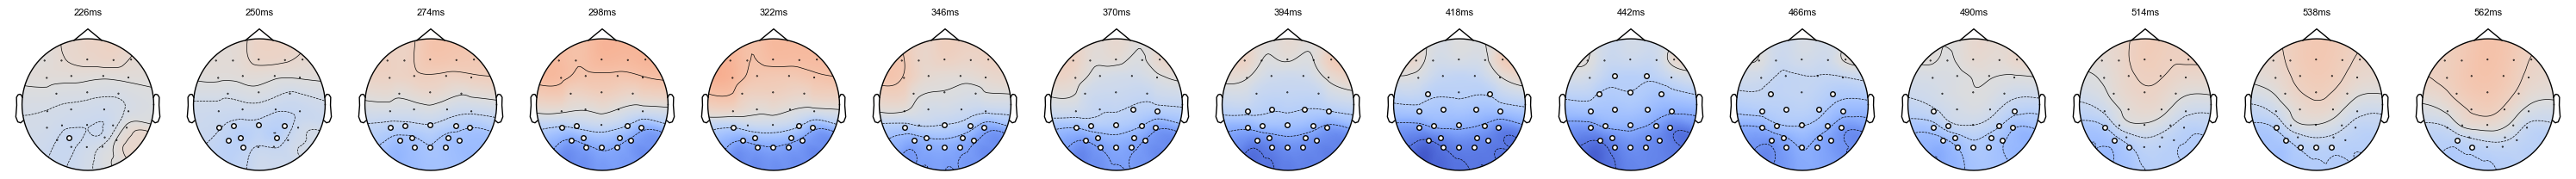

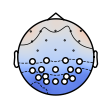

In [18]:
all_clusters_info = []
for c, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        print(f"Significant spatio-temporal cluster found with p-value {p_val:.4f}")
        time_idxs, chan_idxs = c
        curr_times = np.unique(time_idxs)
        fig, axes = plt.subplots(1, len(curr_times), figsize=(2 * len(curr_times), 4))

        for it, t in enumerate(curr_times):
            curr_chans = chan_idxs[time_idxs == t]
            curr_mask = np.zeros(28, dtype=bool)
            curr_mask[curr_chans] = True

            im, _ = mne.viz.plot_topomap(
                haufes_reordered[:, t, :].mean(0),
                info,
                axes=axes[it],
                show=False,
                contours=4,
                vlim=(-0.3, 0.3),
                cmap="coolwarm",
                mask=curr_mask,
                mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
            )
            axes[it].set_title(f"{times[t]}ms", fontsize=8)
        # plt.suptitle(f"{times[curr_times[0]]} - {times[curr_times[-1]]} ms, p={p_val:.4f}", fontsize=12)
        plt.tight_layout()
        plt.savefig(
            f"figures/decoding_desc-{RUN_DESCRIPTION}_HaufeTopomap_cluster_{times[curr_times[0]]}_{times[curr_times[-1]]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        # get the median time of the cluster. If there are an even number of time points, take the average of the two middle time points
        median_time = np.median(curr_times)
        if len(curr_times) % 2 == 0:
            median_times = np.array([median_time - 0.5, median_time + 0.5])
        else:
            median_times = np.array([median_time])
        # plot the topomap that is the average of the mean importances across the median time points of the cluster
        median_diff = haufes_reordered[:, median_times.astype(int), :].mean(1).mean(0)
        median_chans = chan_idxs[np.isin(time_idxs, median_times)]
        median_mask = np.zeros(28, dtype=bool)
        median_mask[median_chans] = True
        im, _ = mne.viz.plot_topomap(
            median_diff,
            info,
            show=False,
            contours=4,
            vlim=(-0.3, 0.3),
            cmap="coolwarm",
            mask=median_mask,
            mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
        )
        plt.savefig(
            f"figures/decoding_desc-{RUN_DESCRIPTION}_HaufeTopomap_clusterMEDIAN_{times[int(median_times[0])]}_{times[int(median_times[-1])]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        all_clusters_info.append(
            {
                "p_value": p_val,
                "time_idxs": time_idxs,
                "chan_idxs": chan_idxs,
                "median_time": median_time,
                "median_chans": median_chans,
            }
        )

Significant spatio-temporal cluster found with p-value 0.0052


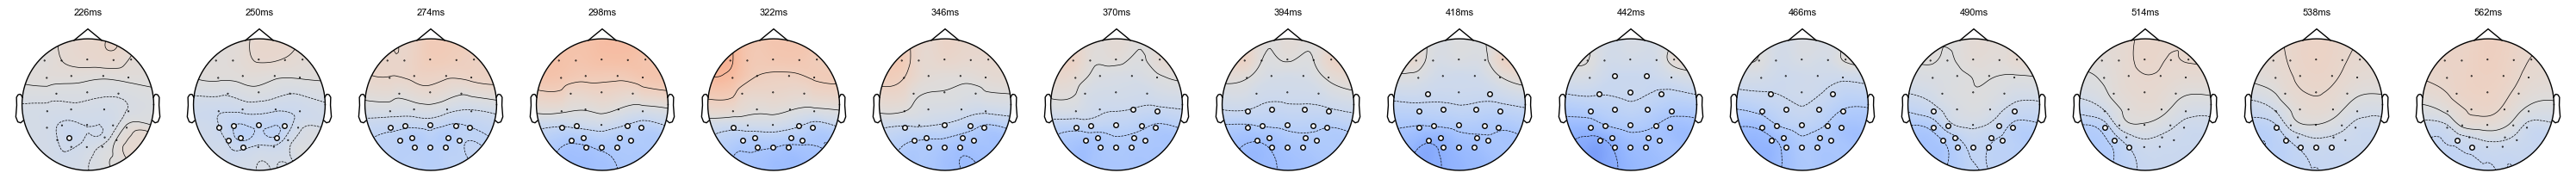

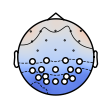

In [19]:
all_clusters_info = []
for c, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        print(f"Significant spatio-temporal cluster found with p-value {p_val:.4f}")
        time_idxs, chan_idxs = c
        curr_times = np.unique(time_idxs)
        fig, axes = plt.subplots(1, len(curr_times), figsize=(2 * len(curr_times), 4))

        for it, t in enumerate(curr_times):
            curr_chans = chan_idxs[time_idxs == t]
            curr_mask = np.zeros(28, dtype=bool)
            curr_mask[curr_chans] = True

            im, _ = mne.viz.plot_topomap(
                haufes_reordered[:, t, :].mean(0) / haufes_reordered[:, t, :].std(0),
                info,
                axes=axes[it],
                show=False,
                contours=4,
                vlim=(-3, 3),
                cmap="coolwarm",
                mask=curr_mask,
                mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
            )
            axes[it].set_title(f"{times[t]}ms", fontsize=8)
        # plt.suptitle(f"{times[curr_times[0]]} - {times[curr_times[-1]]} ms, p={p_val:.4f}", fontsize=12)
        plt.tight_layout()
        plt.show()
        plt.close()
        # get the median time of the cluster. If there are an even number of time points, take the average of the two middle time points
        median_time = np.median(curr_times)
        if len(curr_times) % 2 == 0:
            median_times = np.array([median_time - 0.5, median_time + 0.5])
        else:
            median_times = np.array([median_time])
        # plot the topomap that is the average of the mean importances across the median time points of the cluster
        median_diff = haufes_reordered[:, median_times.astype(int), :].mean(1).mean(0)
        median_chans = chan_idxs[np.isin(time_idxs, median_times)]
        median_mask = np.zeros(28, dtype=bool)
        median_mask[median_chans] = True
        im, _ = mne.viz.plot_topomap(
            median_diff,
            info,
            show=False,
            contours=4,
            vlim=(-0.3, 0.3),
            cmap="coolwarm",
            mask=median_mask,
            mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
        )
        plt.savefig(
            f"figures/decoding_desc-{RUN_DESCRIPTION}_HaufeTopomap_clusterMEDIAN_{times[int(median_times[0])]}_{times[int(median_times[-1])]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        all_clusters_info.append(
            {
                "p_value": p_val,
                "time_idxs": time_idxs,
                "chan_idxs": chan_idxs,
                "median_time": median_time,
                "median_chans": median_chans,
            }
        )

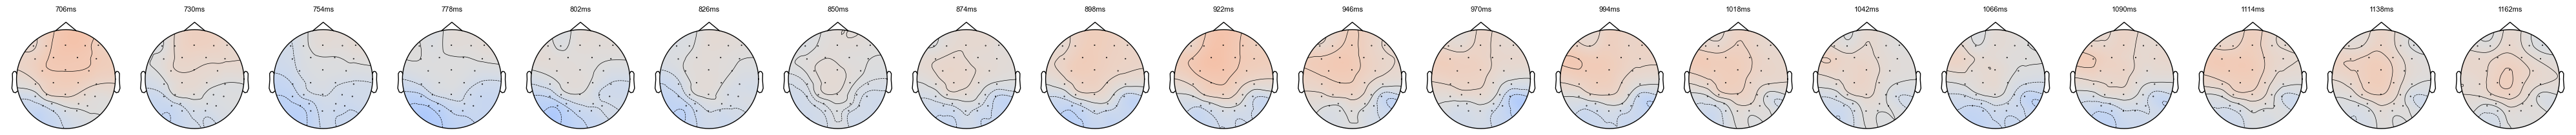

In [20]:
# Examine the TOPO during the later WM cluster to see if it's consistent across tasks
late_WM_cluster_tidx = np.arange(43, 63)

fig, axes = plt.subplots(1, len(late_WM_cluster_tidx), figsize=(2 * len(late_WM_cluster_tidx), 4))

# curr_mask = np.zeros(haufes_reordered.shape[0], dtype=bool)
# curr_mask[chan_idxs] = True
for it, t in enumerate(late_WM_cluster_tidx):
    curr_mask = np.zeros(28, dtype=bool)  # all False

    im, _ = mne.viz.plot_topomap(
        haufes_reordered[:, t, :].mean(0),
        info,
        axes=axes[it],
        show=False,
        contours=4,
        vlim=(-0.3, 0.3),
        cmap="coolwarm",
        mask=curr_mask,
        mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
    )
    axes[it].set_title(f"{times[t]}ms", fontsize=8)

plt.tight_layout()
plt.show()
plt.close()

### Plot just the test results for the 2 training conditions

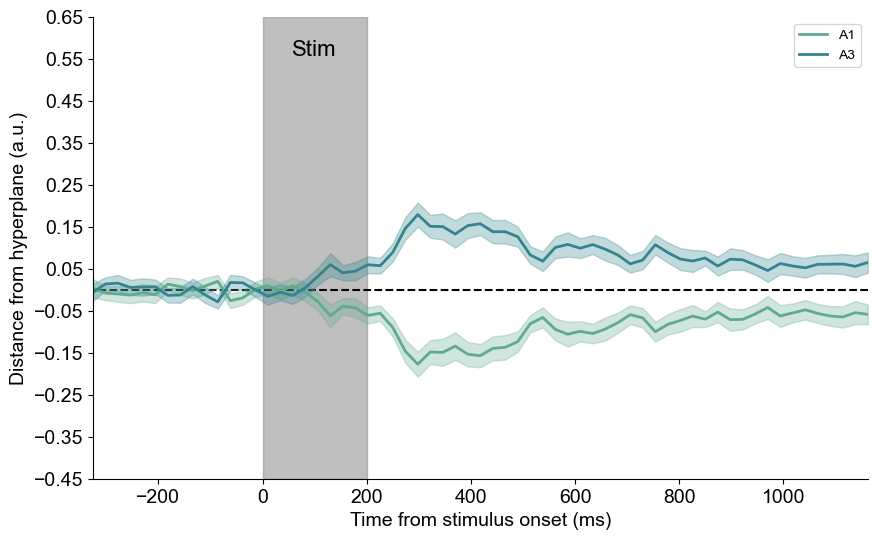

In [21]:
plot_training_conds(preds_mean, preds_lower, preds_upper, times, training_labels, suffix=None)

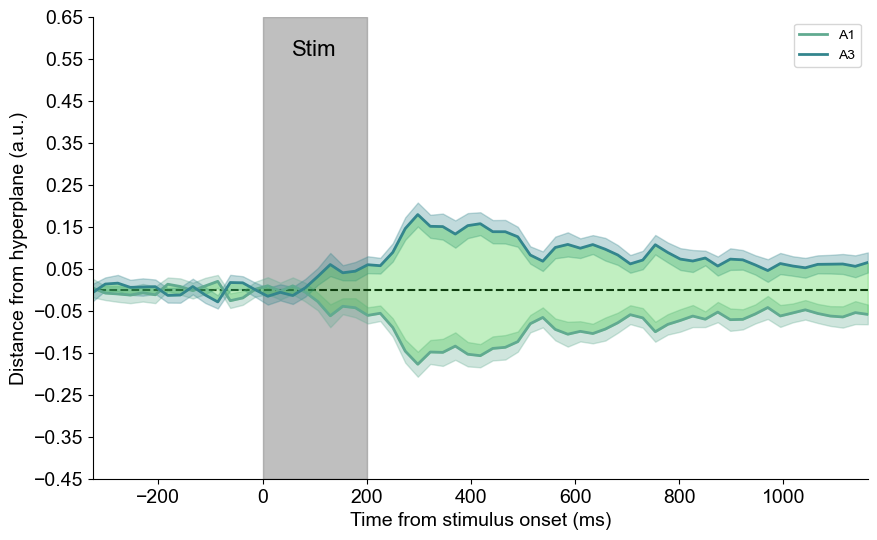

In [22]:
plot_training_conds(
    preds_mean, preds_lower, preds_upper, times, training_labels, suffix="contrastFilled", fill_between=True
)

In [23]:
# plot_individual_subs(preds_per_sub, times, training_labels, interp, conditions, color_map)

## Look at all the conditions in the same task

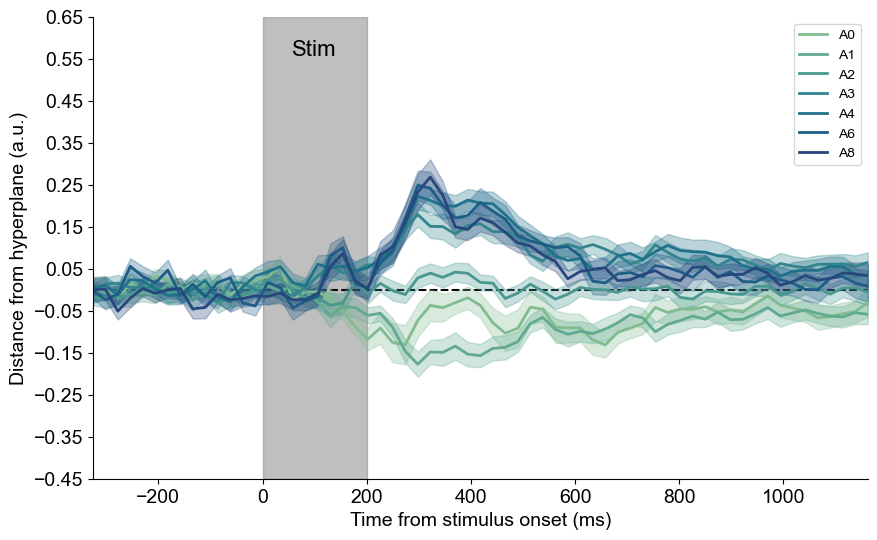

In [24]:
plot_task_conds(preds_mean, preds_lower, preds_upper, times, suffix=None)

# Plot conditions of the other task

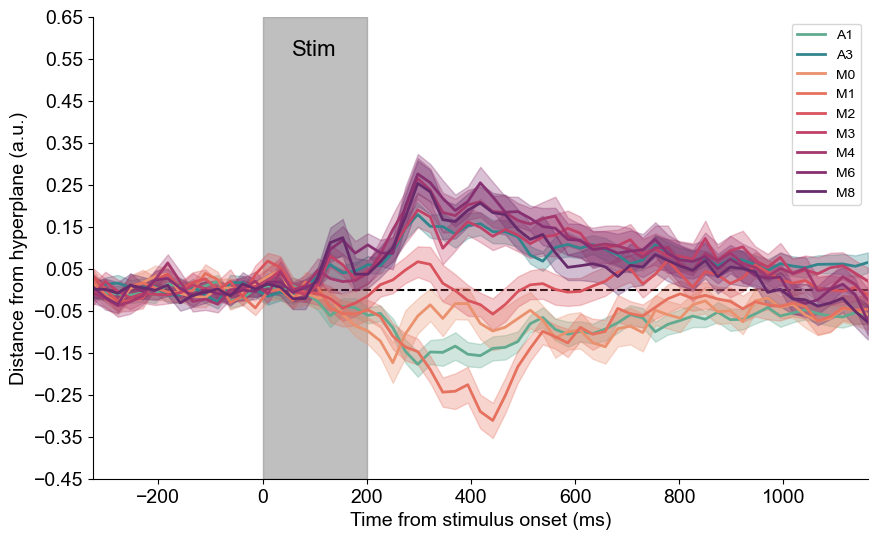

In [25]:
plot_alt_conds(preds_mean, preds_lower, preds_upper, times, suffix=None)

# Plot all conditions

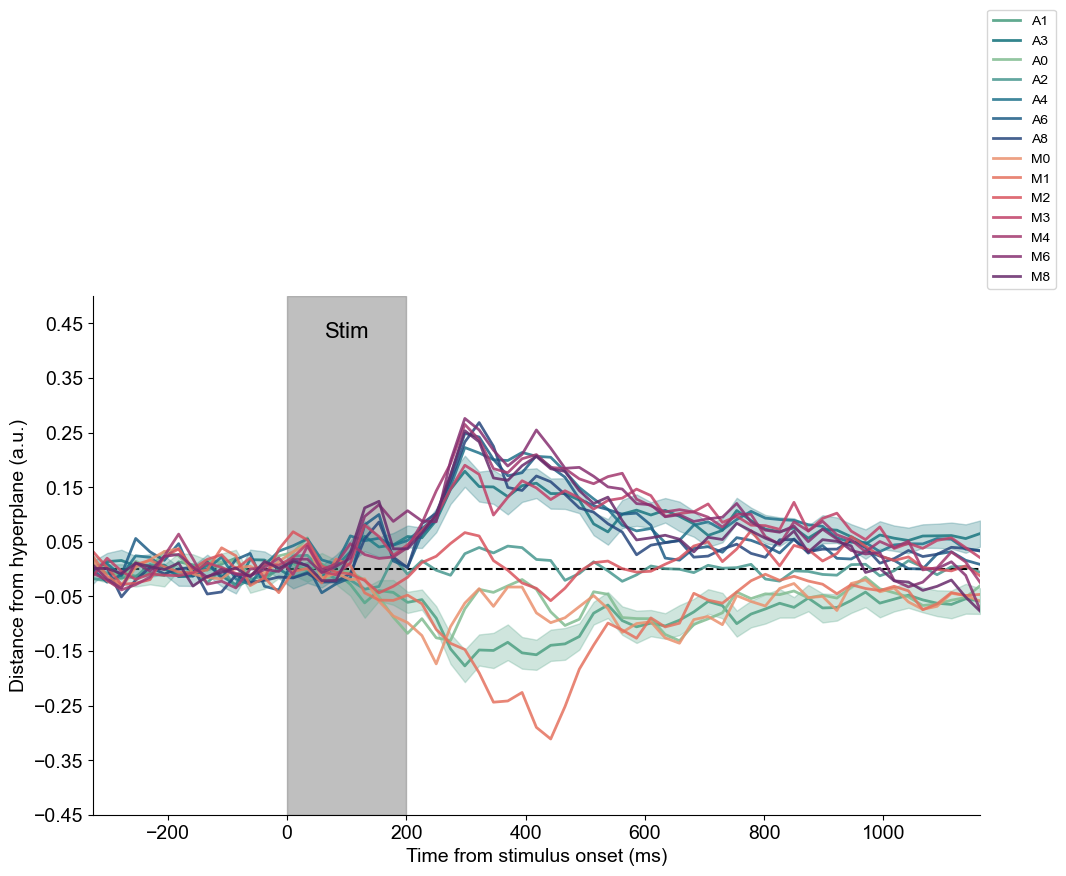

In [26]:
plot_all_conds(preds_mean, preds_lower, preds_upper, times, suffix=None)

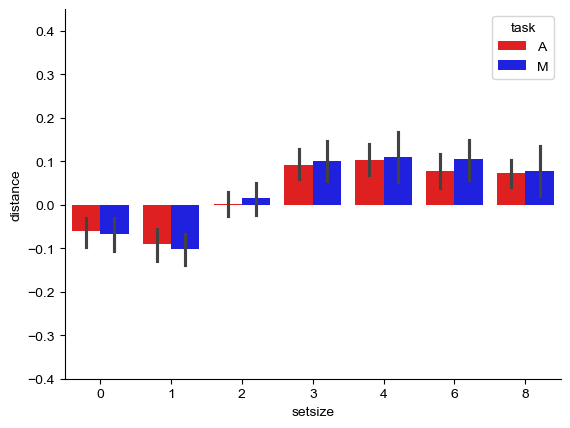

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,2.481921,6,174,0.413653,34.780844,1.972167e-27,1.162968e-14,0.305015,0.491775
1,task,0.004087,1,29,0.004087,0.194112,6.627826e-01,6.627826e-01,0.000722,1.000000
2,setsize * task,0.015921,6,174,0.002653,0.486522,8.178255e-01,7.722609e-01,0.002807,0.772141


In [27]:
aov = plot_bar_plots_ANOVAs(preds_per_sub)
aov

## show a 2 facet barplot, splitting the delay period into first half and last half (300-700; 700-1100)

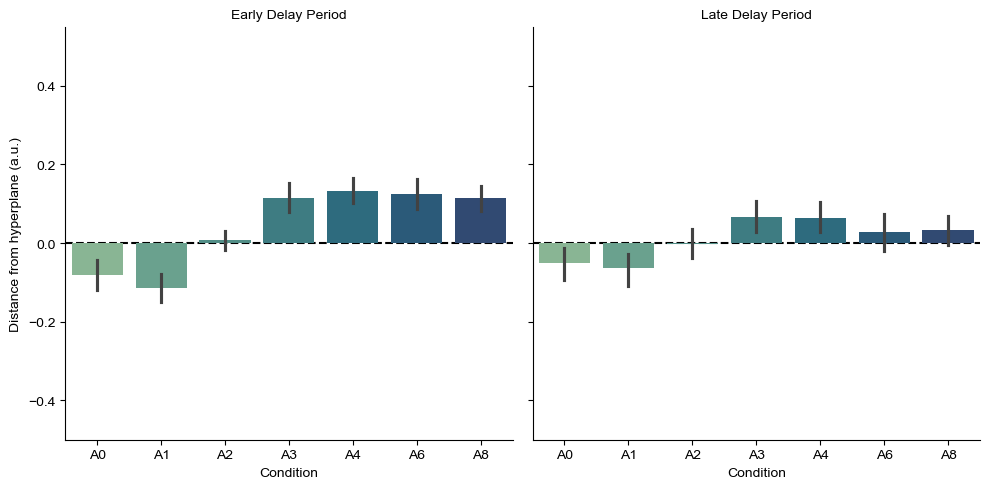

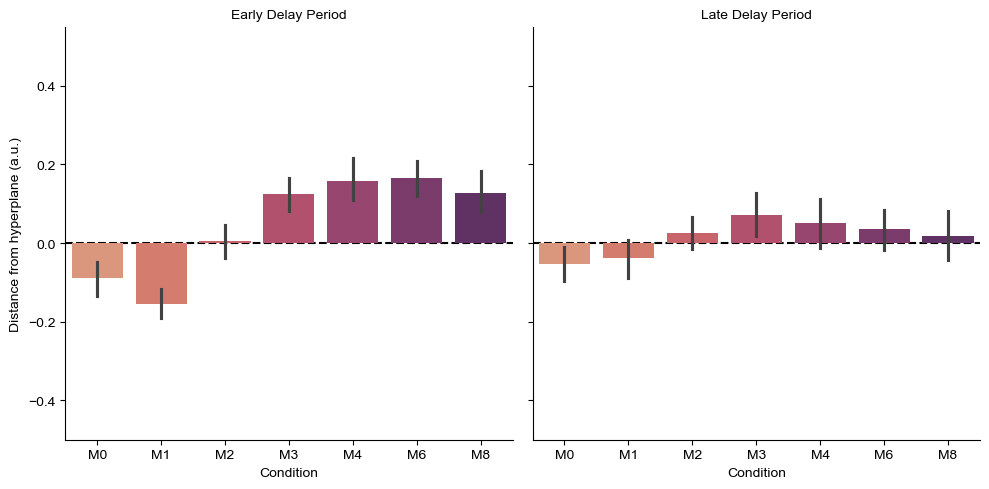

In [28]:
split_half_barplots(preds_per_sub, times, conditions, color_map)

# Plot the contrasts for our 2 training condition pairs

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/mne/stats/parametric.py:60: RuntimeWarning: invalid value encountered in divide
  return np.mean(X, axis=0) / np.sqrt(var / X.shape[0])


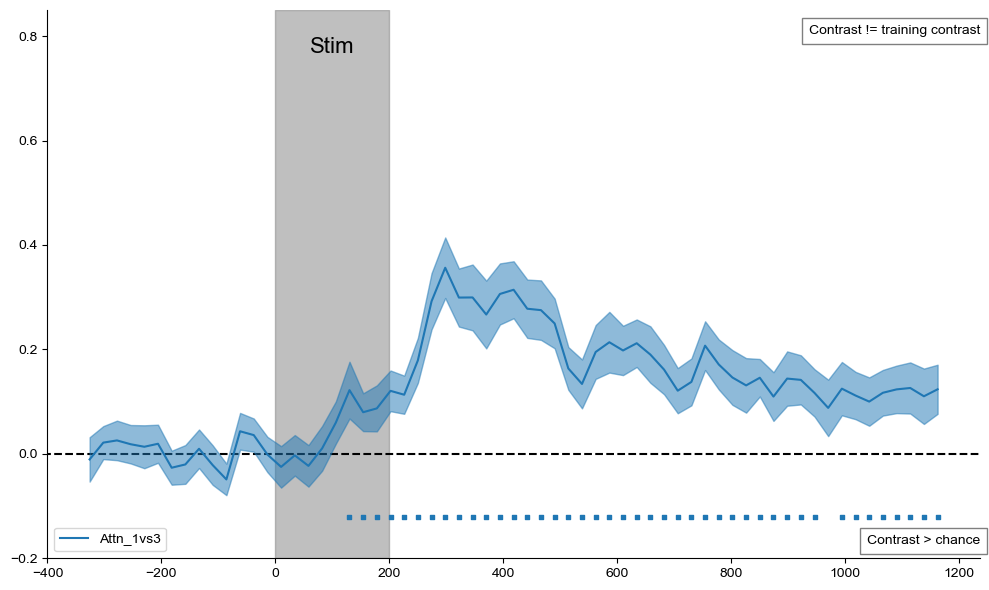

In [29]:
plot_contrasts(preds_per_sub, times, training_labels, suffix="noGen", generalize=False, ylim=(-0.2, 0.85))

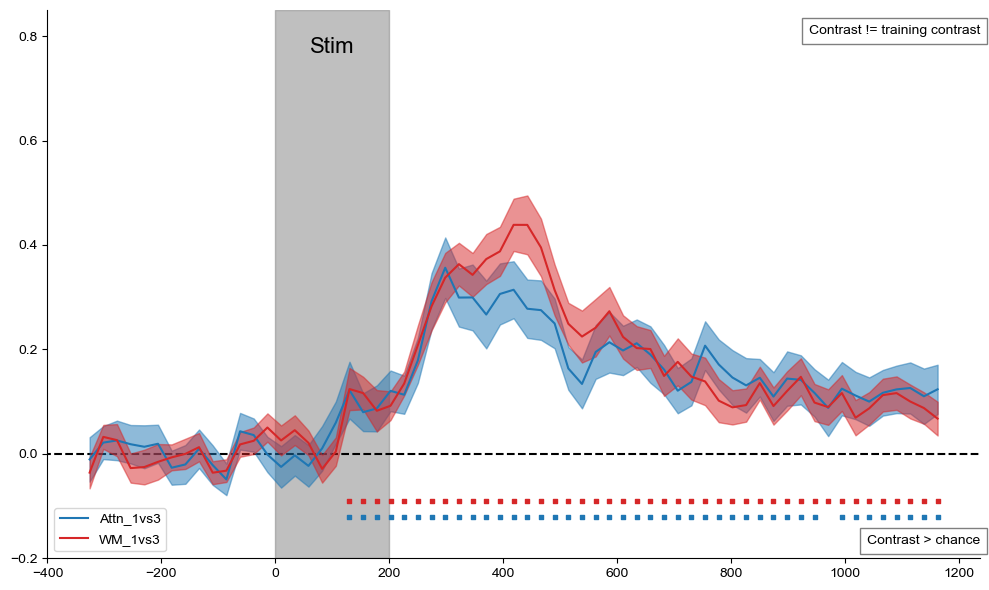

In [30]:
plot_contrasts(preds_per_sub, times, training_labels, suffix=None, ylim=(-0.2, 0.85))

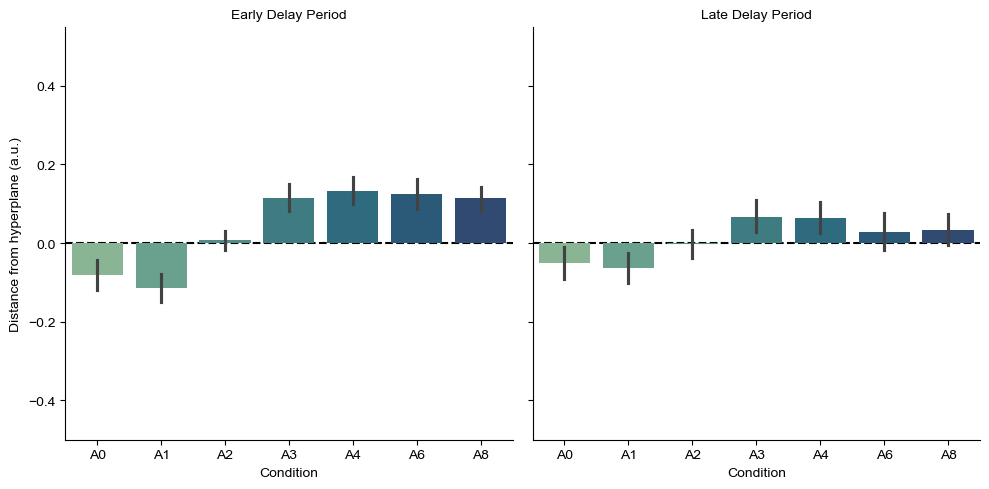

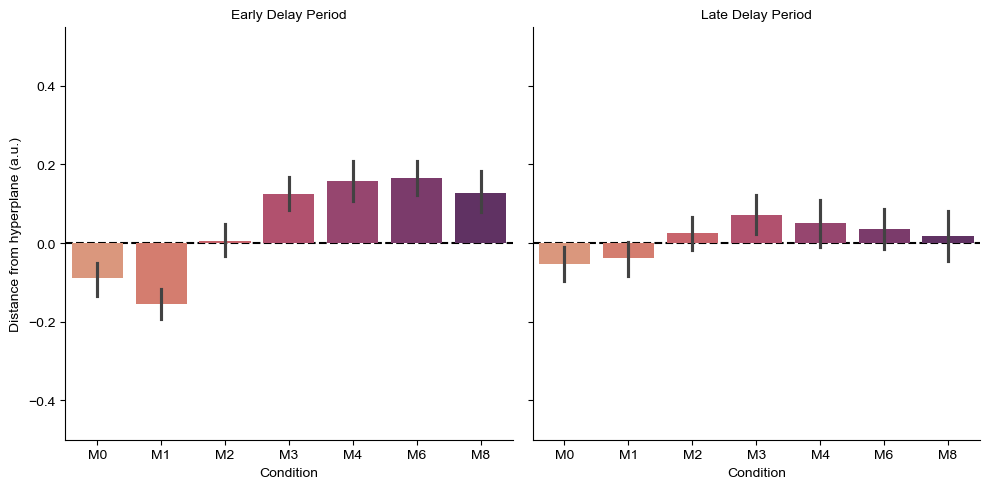

In [31]:
split_half_barplots(preds_per_sub, times, conditions, color_map)

# Looking at Eye & Pupil Predictions!

In [32]:
from statsmodels.stats.multitest import multipletests

In [33]:
def plot_haufe_eyes(haufe_eyes, current_chan_names, suffix):
    eye_feature_clusters = {}
    min_p_values = []
    # for each of the 12 eye features. we will get the cluster-based permutation test results and save out the clusters
    for i in range(haufe_eyes.shape[1]):
        _, feat_clusters, feat_cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
            haufe_eyes[:, i, :], n_permutations=10000, adjacency=None, tail=0
        )
        if len(feat_clusters) > 0:
            print(
                f"Significant spatio-temporal cluster found for eye feature {i} with p-value {feat_cluster_p_values.min():.4f}"
            )
            min_p_values.append(feat_cluster_p_values.min())
            eye_feature_clusters[i] = {
                "clusters": feat_clusters,
                "cluster_p_values": feat_cluster_p_values,
            }
        else:
            eye_feature_clusters[i] = {
                "clusters": [],
                "cluster_p_values": [],
            }

    multitest_results = multipletests(min_p_values, alpha=0.05, method="fdr_bh")
    sig_bool = multitest_results[0]
    sig_pvals = np.array(min_p_values)[sig_bool]
    if len(sig_pvals) > 0:
        print(f"Significant eye features after FDR correction: {np.where(sig_bool)[0]} with p-values {sig_pvals}")
        # use the highest significant p-value as the threshold for plotting
        pval_threshold = sig_pvals.max()
    else:
        print("No significant eye features after FDR correction.")
        pval_threshold = 0  # this will ensure that no clusters are plotted

    # make a figure with a line for each eye feature and a cluster threshold if past significance threshold
    fig, axes = plt.subplots(nrows=haufe_eyes.shape[1], ncols=1, figsize=(6, 1.25 * haufe_eyes.shape[1]), sharex=True)

    for i in eye_feature_clusters.keys():
        curr_haufe = haufe_eyes[:, i, :]
        # pivot into a long format for seaborn plotting
        wide_haufe_df = pd.DataFrame(curr_haufe, columns=times)
        wide_haufe_df["subid"] = np.arange(curr_haufe.shape[0])
        melted_haufe = wide_haufe_df.melt(var_name="time", value_name=current_chan_names[i], id_vars="subid")

        sns.lineplot(x="time", y=current_chan_names[i], data=melted_haufe, ax=axes[i])
        axes[i].axhline(0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max())

        clusters = eye_feature_clusters[i]["clusters"]
        cluster_p_values = eye_feature_clusters[i]["cluster_p_values"]
        sig_clusters = [c for c, p in zip(clusters, cluster_p_values) if p <= pval_threshold]
        if len(sig_clusters) > 0:
            for c in sig_clusters:
                c_start = times[c[0].min()]
                c_end = times[c[0].max()]
                print(f"Plotting significant cluster for eye feature {i} from {c_start} to {c_end} ms")
                axes[i].axvspan(c_start, c_end, color="red", alpha=0.3)
        axes[i].set_ylabel(current_chan_names[i], fontsize=8)
        sns.despine()

    plt.savefig(
        f"figures/decoding_desc-{RUN_DESCRIPTION}_HaufeEyes-{suffix}.png",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )
    plt.show()
    plt.close()

In [34]:
eye_feature_name_map = {
    "pupil_left": "Left Pupil",
    "pupil_right": "Right Pupil",
    "pupil_left_TD": "Left Pupil (TD)",
    "pupil_right_TD": "Right Pupil (TD)",
    "xpos_left": "Left X Position",
    "xpos_right": "Right X Position",
    "ypos_left": "Left Y Position",
    "ypos_right": "Right Y Position",
    "dist_left": "Left Distance",
    "dist_right": "Right Distance",
    "xpos_left_TD": "Left X Position (TD)",
    "xpos_right_TD": "Right X Position (TD)",
    "ypos_left_TD": "Left Y Position (TD)",
    "ypos_right_TD": "Right Y Position (TD)",
    "dist_left_TD": "Left Distance (TD)",
    "dist_right_TD": "Right Distance (TD)",
}

In [35]:
def eye_pipeline(SUFFIX):
    assert SUFFIX in ["EYES", "PUPIL"], "SUFFIX must be either 'EYES' or 'PUPIL'"

    preds_all_eyes, haufe_eyes, times = interp.dataset.get_data(
        None, keys=[f"preds{SUFFIX}", f"Haufe{SUFFIX}", "times"]
    )

    preds_per_sub_eyes = preds_all_eyes.mean(2).mean(
        1
    )  # flatten across folds and then reps (I know order doesn't matter, but like the concepual clarity)

    preds_mean_eyes, preds_upper_eyes, preds_lower_eyes = interp.get_plot_line(
        preds_per_sub_eyes
    )  # get the mean and upper/lower SEM bounds, for pretty plotting

    haufe_eyes = haufe_eyes.mean(2).mean(1)

    curr_chan_idx = pupil_chan_idx if SUFFIX == "PUPIL" else eyeOnly_chan_idx
    current_chan_names = np.array(eye_chan_names)[curr_chan_idx]
    nice_chan_names = [eye_feature_name_map.get(ch, ch) for ch in current_chan_names]

    plot_haufe_eyes(haufe_eyes, nice_chan_names, SUFFIX)

    plot_training_conds(preds_mean_eyes, preds_lower_eyes, preds_upper_eyes, times, training_labels, suffix=SUFFIX)
    plot_task_conds(preds_mean_eyes, preds_lower_eyes, preds_upper_eyes, times, suffix=SUFFIX)
    plot_alt_conds(preds_mean_eyes, preds_lower_eyes, preds_upper_eyes, times, suffix=SUFFIX)
    plot_all_conds(preds_mean_eyes, preds_lower_eyes, preds_upper_eyes, times, suffix=SUFFIX)
    plot_contrasts(preds_per_sub_eyes, times, training_labels, suffix=f"{SUFFIX}noGen", generalize=False)
    plot_contrasts(preds_per_sub_eyes, times, training_labels, suffix=SUFFIX)

Significant spatio-temporal cluster found for eye feature 2 with p-value 0.0011
Significant spatio-temporal cluster found for eye feature 3 with p-value 0.0021
Significant eye features after FDR correction: [0 1] with p-values [0.0011 0.0021]
Plotting significant cluster for eye feature 2 from 442 to 682 ms
Plotting significant cluster for eye feature 3 from 442 to 682 ms


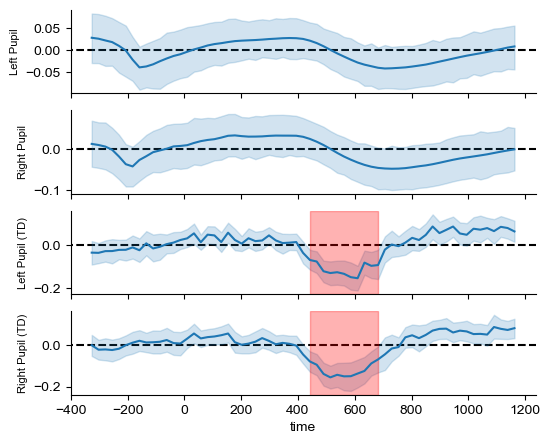

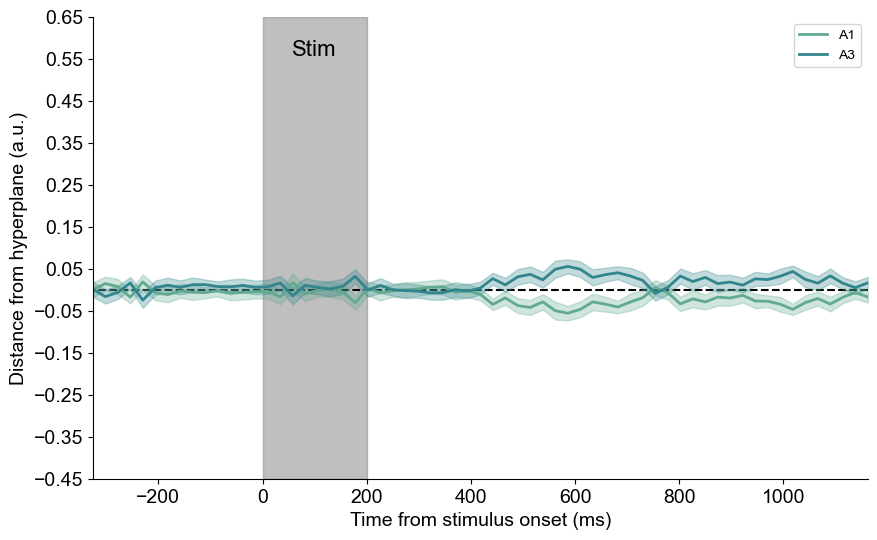

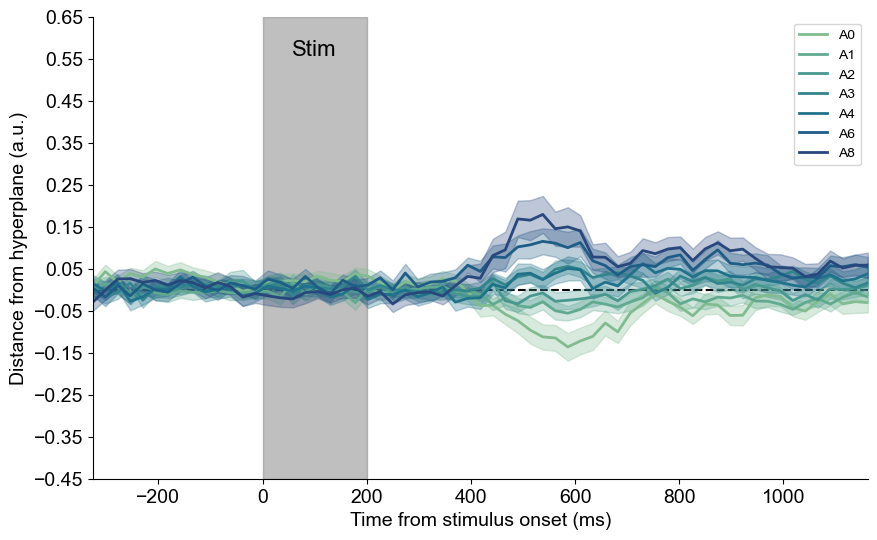

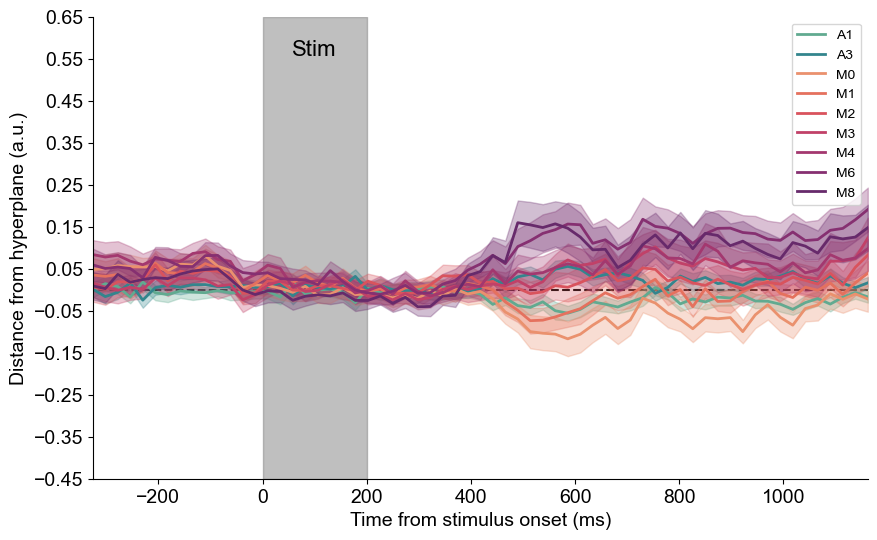

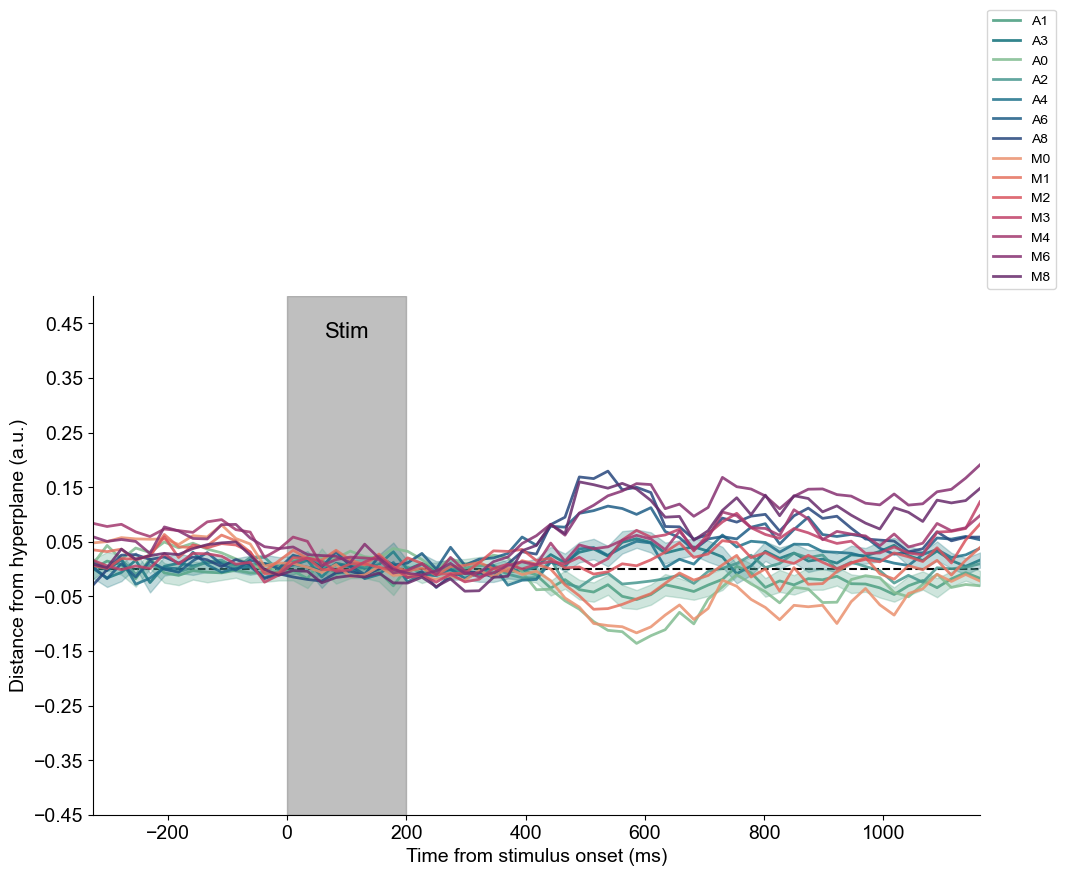

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/mne/stats/parametric.py:60: RuntimeWarning: invalid value encountered in divide
  return np.mean(X, axis=0) / np.sqrt(var / X.shape[0])


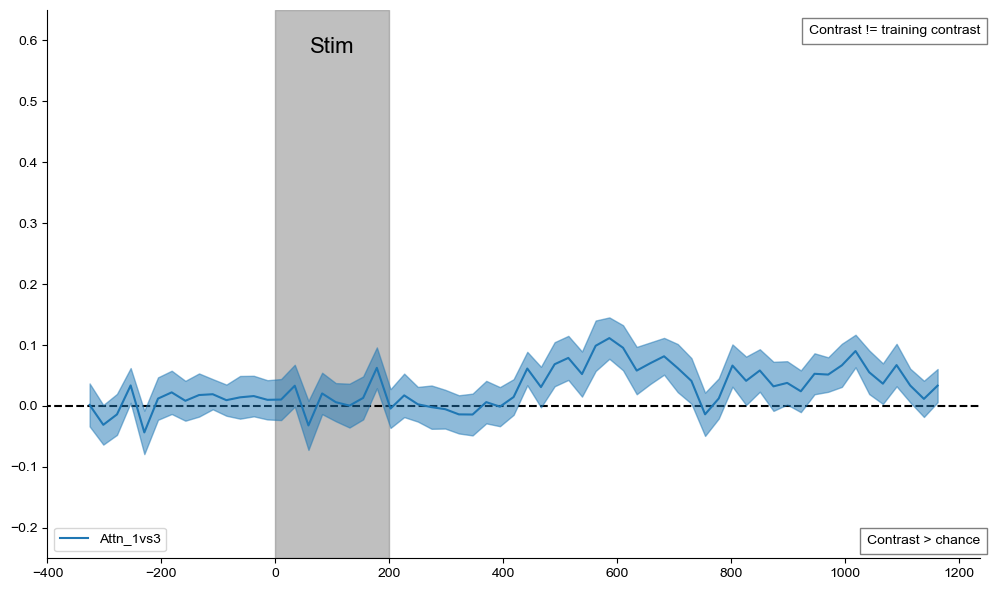

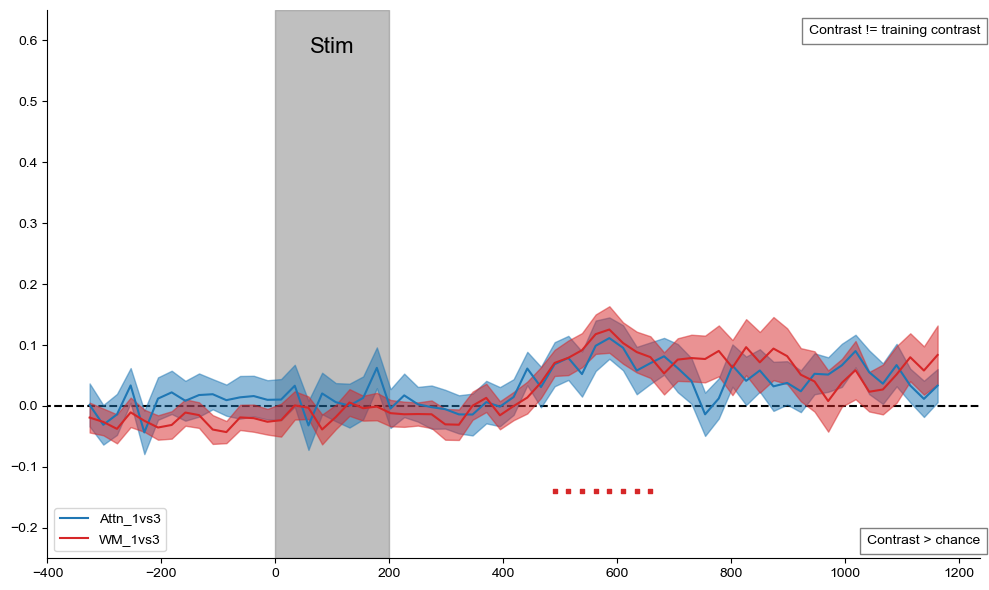

In [36]:
eye_pipeline("PUPIL")

Significant spatio-temporal cluster found for eye feature 0 with p-value 0.2183
Significant spatio-temporal cluster found for eye feature 2 with p-value 0.1435
Significant spatio-temporal cluster found for eye feature 6 with p-value 0.9508
Significant spatio-temporal cluster found for eye feature 7 with p-value 0.7224
Significant spatio-temporal cluster found for eye feature 8 with p-value 0.0310
Significant spatio-temporal cluster found for eye feature 9 with p-value 0.9307
Significant spatio-temporal cluster found for eye feature 10 with p-value 0.8580
Significant spatio-temporal cluster found for eye feature 11 with p-value 0.7364
No significant eye features after FDR correction.


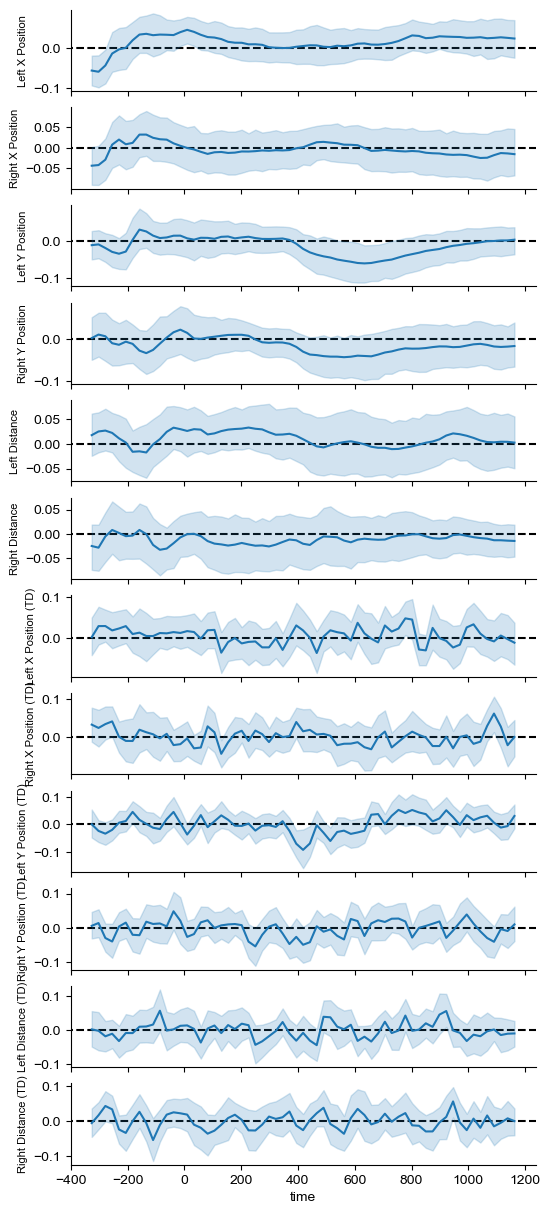

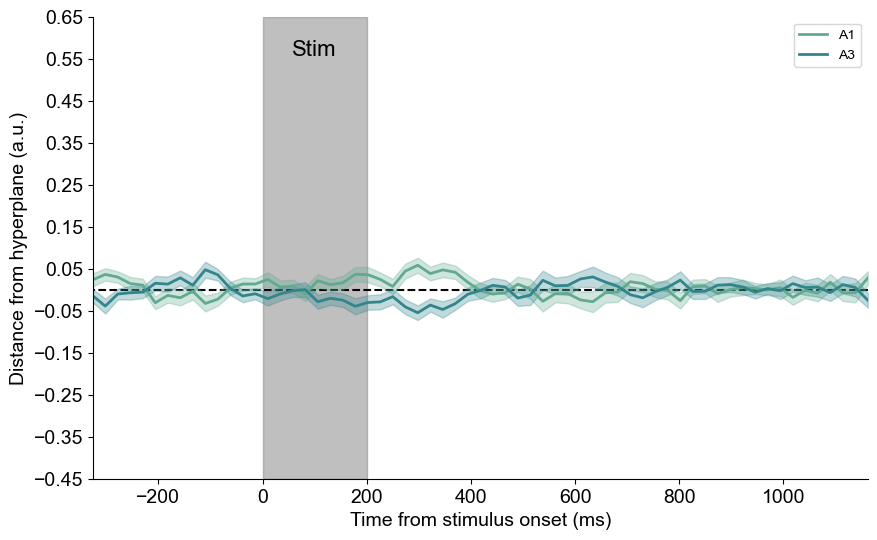

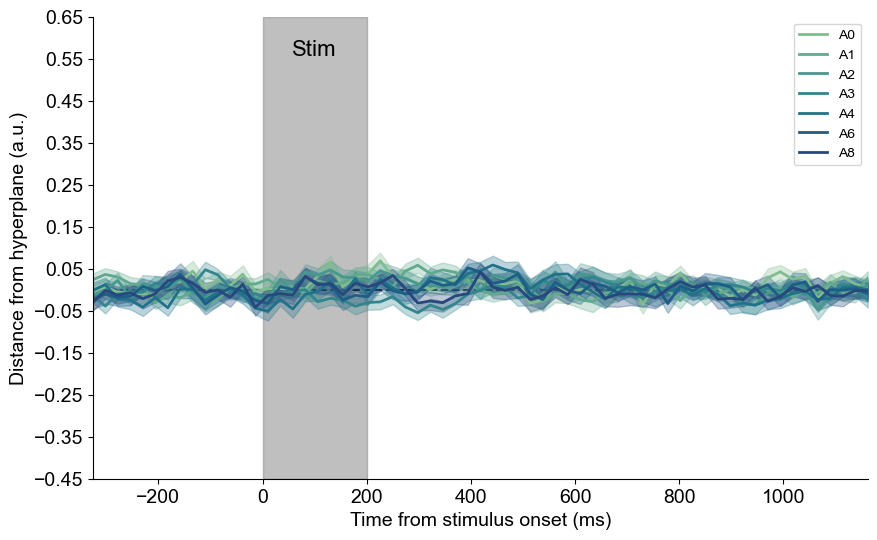

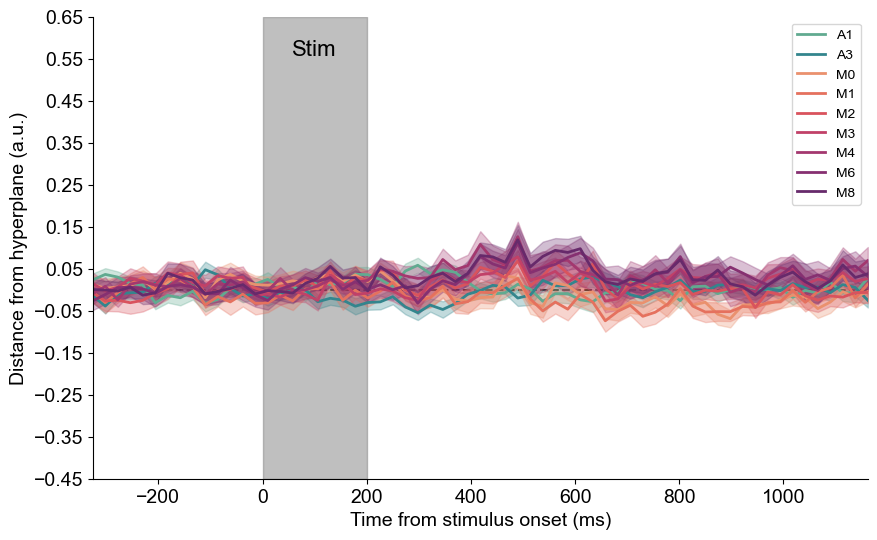

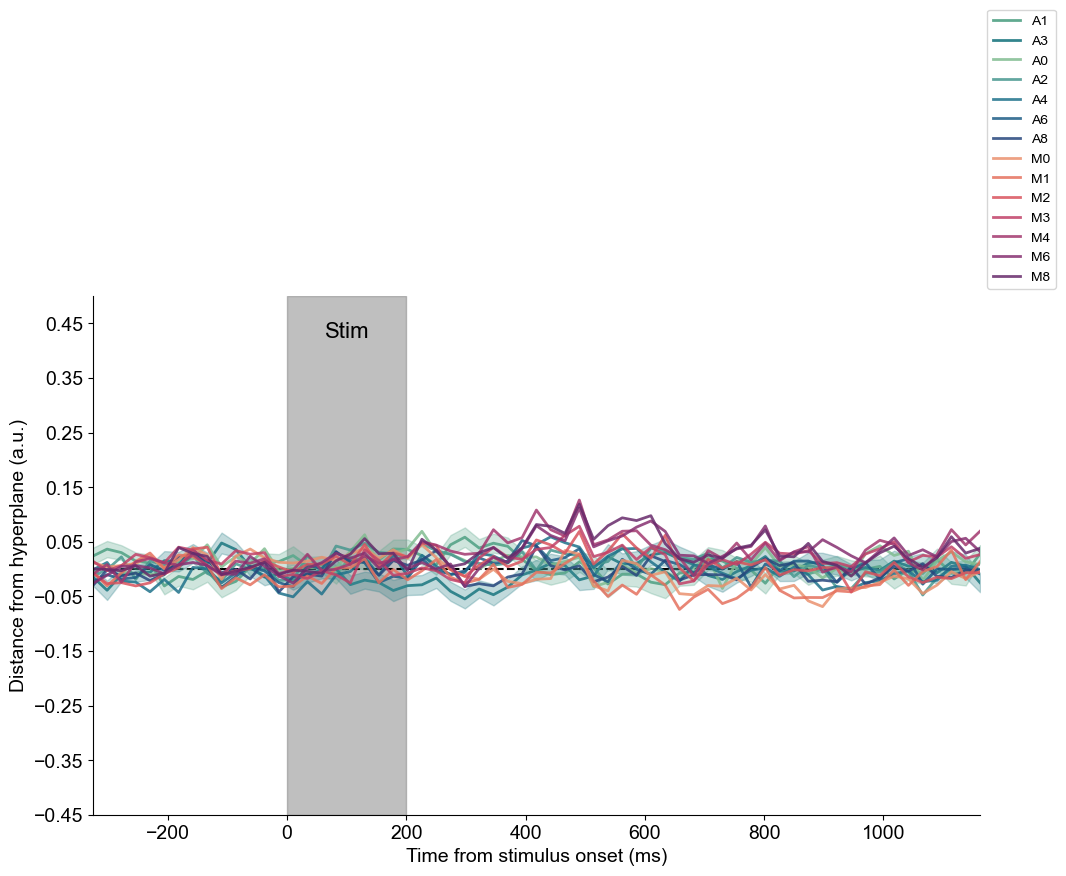

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/mne/stats/parametric.py:60: RuntimeWarning: invalid value encountered in divide
  return np.mean(X, axis=0) / np.sqrt(var / X.shape[0])


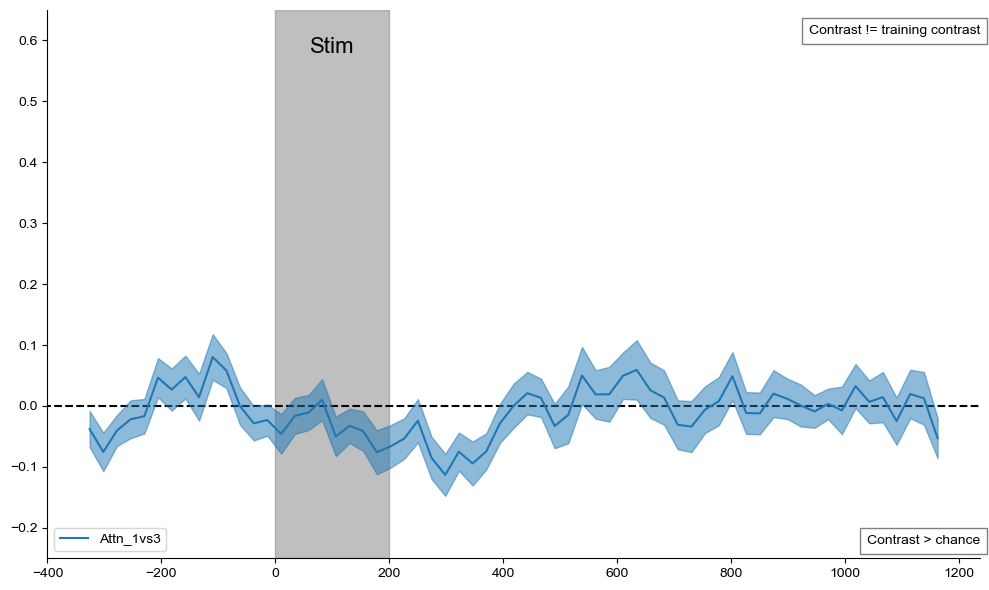

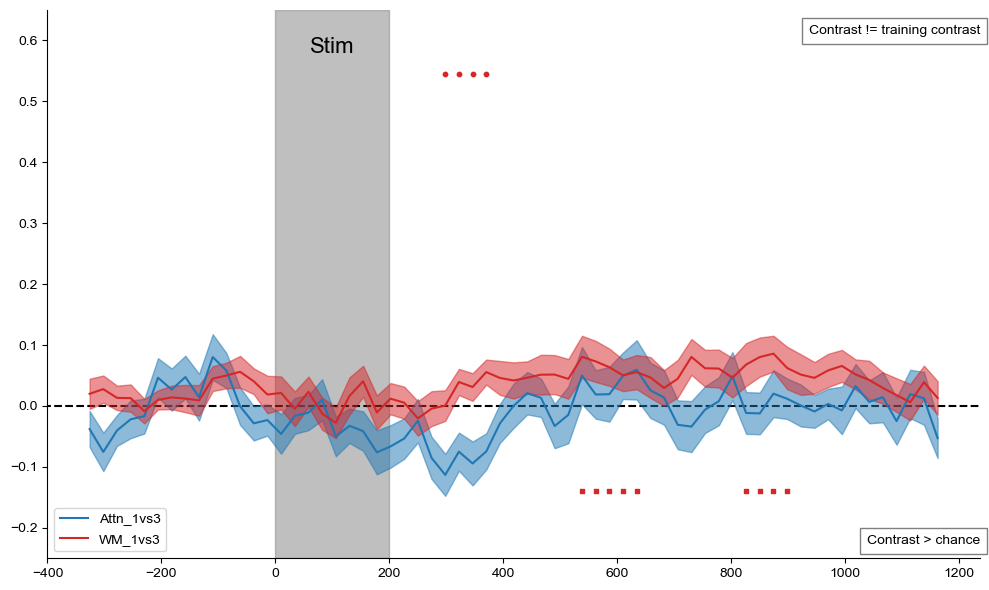

In [37]:
eye_pipeline("EYES")

# Look at the predictions based on what the model was trained on, attention or WM

In [38]:
attn_interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=["A1vsA3"],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["times", "preds", "Haufe", "weights"],
)
preds_attn, times, haufe_attn, weights_attn = attn_interp.dataset.get_data(
    None, keys=["preds", "times", "Haufe", "weights"]
)
preds_attn_per_sub = preds_attn.mean(2).mean(1)[:, delay_window, :].mean(1)
full_df_attn = pd.DataFrame(preds_attn_per_sub, columns=conditions)
full_df_attn["subject"] = full_df_attn.index.values
melted_df_attn = full_df_attn.melt(id_vars="subject", var_name="condition", value_name="distance")
melted_df_attn.loc[:, "task"] = melted_df_attn.condition.str[0]
melted_df_attn.loc[:, "setsize"] = melted_df_attn.condition.str[1]
melted_df_attn["training_conditions"] = "Attention"

del attn_interp

In [39]:
wm_interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=["M1vsM3"],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["preds", "Haufe", "weights"],
)
preds_wm, haufe_wm, weights_wm = wm_interp.dataset.get_data(None, keys=["preds", "Haufe", "weights"])
preds_wm_per_sub = preds_wm.mean(2).mean(1)[:, delay_window, :].mean(1)
full_df_wm = pd.DataFrame(preds_wm_per_sub, columns=conditions)
full_df_wm["subject"] = full_df_wm.index.values
melted_df_wm = full_df_wm.melt(id_vars="subject", var_name="condition", value_name="distance")
melted_df_wm.loc[:, "task"] = melted_df_wm.condition.str[0]
melted_df_wm.loc[:, "setsize"] = melted_df_wm.condition.str[1]
melted_df_wm["training_conditions"] = "Working Memory"

combined_df = pd.concat([melted_df_attn, melted_df_wm], axis=0).reset_index(drop=True)

del wm_interp

# Difference in Haufe between WM and Attention (WM - Attention)

In [40]:
haufe_task_diff = haufe_wm.mean(2).mean(1) - haufe_attn.mean(2).mean(1)

haufe_task_diff_reordered = np.moveaxis(haufe_task_diff, 2, 1)

t_obs, clusters, cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
    haufe_task_diff_reordered, n_permutations=10000, adjacency=adjacency, tail=0
)

Significant spatio-temporal cluster found with p-value 0.0135


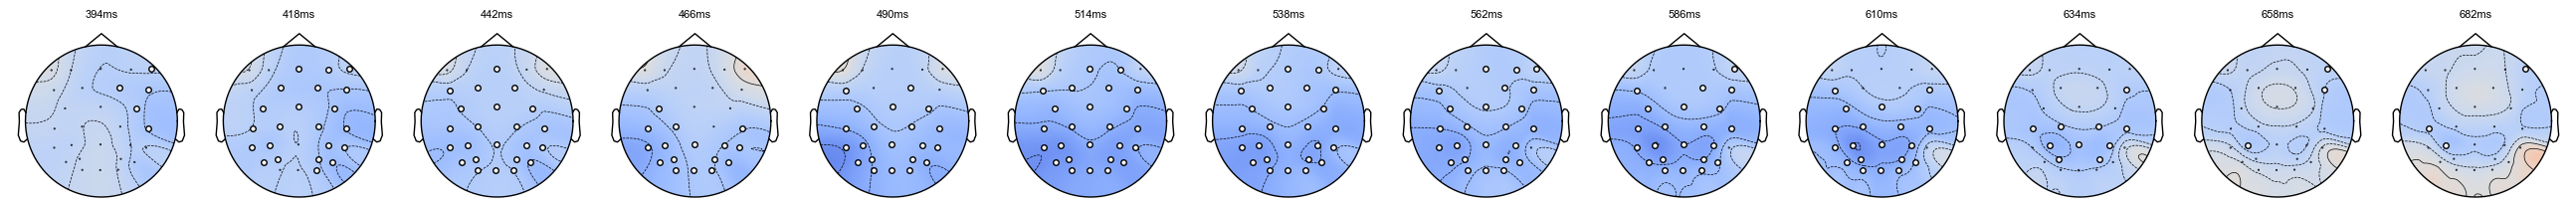

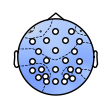

In [41]:
all_diff_clusters_info = []
for c, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        print(f"Significant spatio-temporal cluster found with p-value {p_val:.4f}")
        time_idxs, chan_idxs = c
        curr_times = np.unique(time_idxs)
        fig, axes = plt.subplots(1, len(curr_times), figsize=(2 * len(curr_times), 4))

        for it, t in enumerate(curr_times):
            curr_chans = chan_idxs[time_idxs == t]
            curr_mask = np.zeros(28, dtype=bool)
            curr_mask[curr_chans] = True

            im, _ = mne.viz.plot_topomap(
                haufe_task_diff_reordered[:, t, :].mean(0),
                info,
                axes=axes[it],
                show=False,
                contours=4,
                vlim=(-0.3, 0.3),
                cmap="coolwarm",
                mask=curr_mask,
                mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
            )
            axes[it].set_title(f"{times[t]}ms", fontsize=8)
        plt.tight_layout()
        plt.savefig(
            f"figures/decoding_desc_HaufeTopomap_taskDiff_cluster_{times[curr_times[0]]}_{times[curr_times[-1]]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        # get the median time of the cluster. If there are an even number of time points, take the average of the two middle time points
        median_time = np.median(curr_times)
        if len(curr_times) % 2 == 0:
            median_times = np.array([median_time - 0.5, median_time + 0.5])
        else:
            median_times = np.array([median_time])
        # plot the topomap that is the average of the mean importances across the median time points of the cluster
        median_diff = haufe_task_diff_reordered[:, median_times.astype(int), :].mean(1).mean(0)
        median_chans = chan_idxs[np.isin(time_idxs, median_times)]
        median_mask = np.zeros(28, dtype=bool)
        median_mask[median_chans] = True
        im, _ = mne.viz.plot_topomap(
            median_diff,
            info,
            show=False,
            contours=4,
            vlim=(-0.3, 0.3),
            cmap="coolwarm",
            mask=median_mask,
            mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
        )
        plt.savefig(
            f"figures/decoding_desc_HaufeTopomap_taskDiff_clusterMEDIAN_{times[int(median_times[0])]}_{times[int(median_times[-1])]}ms.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()
        all_diff_clusters_info.append(
            {
                "p_value": p_val,
                "time_idxs": time_idxs,
                "chan_idxs": chan_idxs,
                "median_time": median_time,
                "median_chans": median_chans,
            }
        )
        # plt.colorbar(im, fraction=0.01, pad=0.04).set_label("Haufe Importance Difference (WM - Attn)", fontsize=12)

# Difference in Weights between WM and Attention
### If they differ across extra times compared to above, it could be due to systematic differences in noise

In [42]:
weights_task_diff = weights_wm.mean(2).mean(1) - weights_attn.mean(2).mean(1)

weights_task_diff_reordered = np.moveaxis(weights_task_diff, 2, 1)

t_obs, clusters, cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
    weights_task_diff_reordered, n_permutations=10000, adjacency=adjacency, tail=0
)
cluster_p_values

array([0.9332, 0.9999, 0.9999, 1.    , 0.9447, 1.    , 1.    , 1.    ,
       1.    , 1.    , 0.8473, 1.    , 1.    , 1.    , 0.9993, 1.    ,
       0.256 , 1.    , 1.    , 1.    , 0.9995, 0.9366, 1.    , 1.    ,
       0.9999, 1.    , 0.9998, 0.9998, 1.    , 0.9978, 0.9103, 1.    ,
       0.9813, 1.    , 1.    , 0.9914, 0.9765, 1.    , 0.9998, 1.    ,
       0.9863, 1.    , 1.    , 1.    , 0.9978, 0.993 , 1.    , 1.    ,
       0.5633, 1.    , 1.    , 1.    , 0.516 , 0.9924, 0.9999, 1.    ,
       0.9904])

In [43]:
for c, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        print(f"Significant spatio-temporal cluster found with p-value {p_val:.4f}")
        time_idxs, chan_idxs = c
        curr_times = np.unique(time_idxs)
        fig, axes = plt.subplots(1, len(curr_times), figsize=(2 * len(curr_times), 4))

        curr_mask[chan_idxs] = True
        for it, t in enumerate(curr_times):
            curr_chans = chan_idxs[time_idxs == t]
            curr_mask = np.zeros(28, dtype=bool)
            curr_mask[curr_chans] = True

            im, _ = mne.viz.plot_topomap(
                weights_task_diff_reordered[:, t, :].mean(0),
                info,
                axes=axes[it],
                show=False,
                contours=4,
                # vlim=(-0.3, 0.3),
                cmap="coolwarm",
                mask=curr_mask,
                mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
            )
            axes[it].set_title(f"{times[t]}ms", fontsize=8)
        plt.tight_layout()
        # plt.savefig(
        #     f"figures/decoding_desc_HaufeTopomap_taskDiff_cluster_{times[curr_times[0]]}_{times[curr_times[-1]]}ms.png",
        #     dpi=300,
        #     bbox_inches="tight",
        # )
        plt.show()
        plt.close()
        # get the median time of the cluster. If there are an even number of time points, take the average of the two middle time points
        median_time = np.median(curr_times)
        if len(curr_times) % 2 == 0:
            median_times = np.array([median_time - 0.5, median_time + 0.5])
        else:
            median_times = np.array([median_time])
        # plot the topomap that is the average of the mean importances across the median time points of the cluster
        median_diff = weights_task_diff_reordered[:, median_times.astype(int), :].mean(1).mean(0)
        median_chans = chan_idxs[np.isin(time_idxs, median_times)]
        median_mask = np.zeros(28, dtype=bool)
        median_mask[median_chans] = True
        im, _ = mne.viz.plot_topomap(
            median_diff,
            info,
            show=False,
            contours=4,
            # vlim=(-0.3, 0.3),
            cmap="coolwarm",
            mask=median_mask,
            mask_params=dict(marker="o", markerfacecolor="w", markersize=4),
        )
        # plt.savefig(
        #     f"figures/decoding_desc_HaufeTopomap_taskDiff_clusterMEDIAN_{times[int(median_times[0])]}_{times[int(median_times[-1])]}ms.png",
        #     dpi=300,
        #     transparent=True,
        #     bbox_inches="tight",
        # )
        plt.show()
        plt.close()

# Back to generalization

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/mne/stats/parametric.py:60: RuntimeWarning: invalid value encountered in divide
  return np.mean(X, axis=0) / np.sqrt(var / X.shape[0])


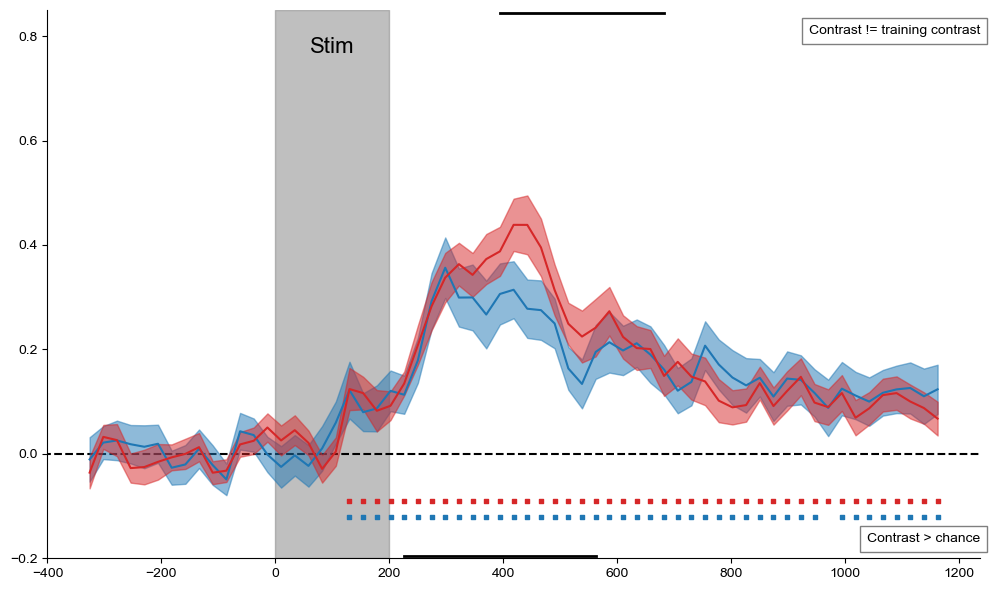

In [44]:
generalize = True
ylim = (-0.2, 0.85)

# Attention
Attn_conds = conditions.index("A1"), conditions.index("A3")
Attn_contrast = preds_per_sub[:, :, Attn_conds[1]] - preds_per_sub[:, :, Attn_conds[0]]

# Memory
WM_conds = conditions.index("M1"), conditions.index("M3")
WM_contrast = preds_per_sub[:, :, WM_conds[1]] - preds_per_sub[:, :, WM_conds[0]]

if "M1" in training_labels and "M3" in training_labels:
    cond_scores = [WM_contrast, Attn_contrast]
    labels = ["WM_1vs3", "Attn_1vs3"]
else:
    cond_scores = [Attn_contrast, WM_contrast]
    labels = ["Attn_1vs3", "WM_1vs3"]

color_palette = {
    "WM_1vs3": "tab:red",
    "Attn_1vs3": "tab:blue",
}

fig, ax = plt.subplots(1, 1, figsize=(10, 6))

if not generalize:
    cond_scores = cond_scores[:1]

for i, curr_scores in enumerate(cond_scores):

    mean, upper, lower = interp.get_plot_line(curr_scores)
    ax.plot(times, mean, color_palette[labels[i]], label=labels[i])
    ax.fill_between(times, upper, lower, color=color_palette[labels[i]], alpha=0.5)

    _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
        curr_scores, n_permutations=5000, tail=1
    )  # NOTE: checking above chance
    for c, p_val in zip(clusters, clusters_pv):
        if p_val < 0.05:
            plt.scatter(
                times[c],
                np.ones(len(times[c])) * (ylim[0] + 0.05 + (i + 1) * 0.03),
                marker="s",
                s=10,
                c=color_palette[labels[i]],
            )

    # now compare the contrast to the training contrast
    if RUN_DESCRIPTION == "A1vsA3":
        train_contrast = Attn_contrast
    elif RUN_DESCRIPTION == "M1vsM3":
        train_contrast = WM_contrast
    diff_contrast = curr_scores - train_contrast
    _, clusters, clusters_pv, _ = permutation_cluster_1samp_test(
        diff_contrast, n_permutations=5000, tail=0
    )  # NOTE: two-tailed here
    for c, p_val in zip(clusters, clusters_pv):
        if p_val < 0.05:
            plt.scatter(
                times[c],
                np.ones(len(times[c]))
                * (
                    ylim[1] - 0.075 - i * 0.03
                ),  # don't need to shift (i+1) this since cond 0 will never be different from itself
                marker="o",
                s=10,
                c=color_palette[labels[i]],
            )

plt.legend(loc="lower left")

plt.axhline(
    0, color="black", linestyle="--", alpha=1, zorder=-1, xmin=times.min(), xmax=times.max()
)  # plot theoretical chance level

ax.set_ylim(ylim)
_ = interp.plot_trial_phases(ax, interp.trial_phases, ylim=ylim)
sns.despine()
plt.tight_layout()

ax.text(
    1,
    0.025,
    "Contrast > chance",
    verticalalignment="bottom",
    horizontalalignment="right",
    transform=ax.transAxes,
    fontsize=10,
    bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
)
ax.text(
    1,
    0.95,
    "Contrast != training contrast",
    verticalalignment="bottom",
    horizontalalignment="right",
    transform=ax.transAxes,
    fontsize=10,
    bbox={"facecolor": "white", "alpha": 0.5, "pad": 5},
)

# for each cluster, plot a black line above the x-axis spanning the time points in the cluster, to visually indicate the significant clusters
for c_info in all_clusters_info:
    c = c_info["time_idxs"]
    plt.plot(times[c], np.ones(len(c)) * (ylim[0] + 0.005), color="black", linewidth=2)

# for each difference cluster, plot a black line below the top of the y-axis spanning the time points in the cluster, to visually indicate the significant clusters
for c_info in all_diff_clusters_info:
    c = c_info["time_idxs"]
    plt.plot(times[c], np.ones(len(c)) * (ylim[1] - 0.005), color="black", linewidth=2)


ax.get_legend().remove()

plt.savefig(
    f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_contrasts{f'_noGen' if not generalize else ''}_haufeClustersMarked.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    f"figures/decoding_timecourse_desc-{RUN_DESCRIPTION}_contrasts{f'_noGen' if not generalize else ''}_haufeClustersMarked.svg",
    bbox_inches="tight",
    transparent=True,
)

plt.show()
plt.close()

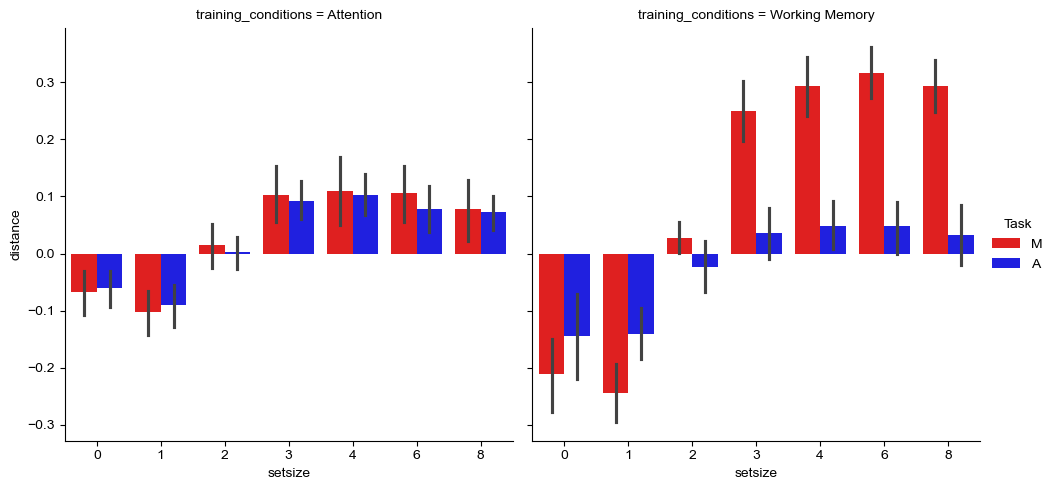

In [45]:
g = sns.FacetGrid(
    combined_df,
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"M": "red", "A": "blue"},
    order=["0", "1", "2", "3", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
plt.savefig(f"figures/{RUN_DESCRIPTION}_model_comparison_barplot_byModel.png", bbox_inches="tight", transparent=True)
plt.show()
plt.close()

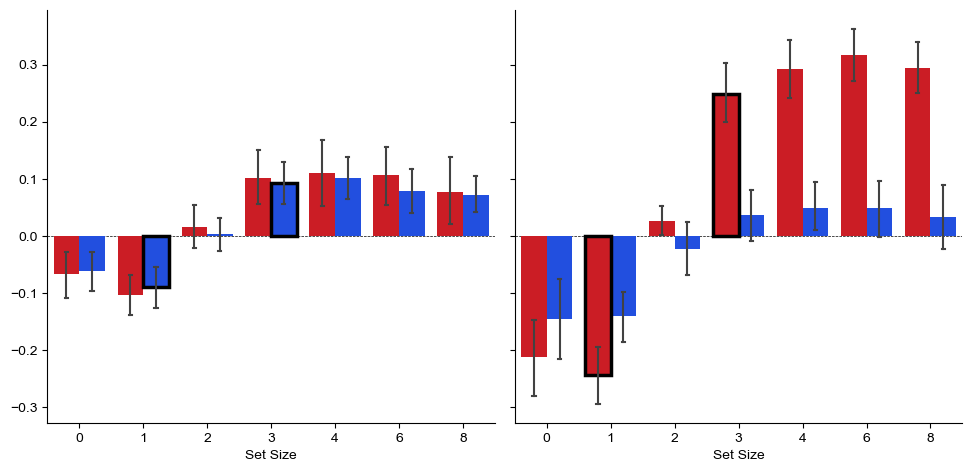

In [56]:
def barplot_with_aligned_outlines(data, x, y, hue, **kwargs):
    order = kwargs.get("order", ["0", "1", "2", "3", "4", "6", "8"])
    hue_order = kwargs.get("hue_order", ["M", "A"])

    ax = sns.barplot(
        data=data,
        x=x,
        y=y,
        hue=hue,
        **kwargs,
    )

    training_condition = data["training_conditions"].iloc[0]
    aligned_task = "A" if training_condition == "Attention" else "M"

    n_hues = len(hue_order)
    bar_width = 0.8 / n_hues

    # Keep all bars below the highlighted outlines.
    for patch in ax.patches:
        patch.set_zorder(1)

    # Highlight the aligned training-condition bars.
    for setsize in ["1", "3"]:
        x_idx = order.index(setsize)
        hue_idx = hue_order.index(aligned_task)
        expected_center = x_idx + (hue_idx - (n_hues - 1) / 2) * bar_width

        matching_bars = [
            patch for patch in ax.patches if abs(patch.get_x() + patch.get_width() / 2 - expected_center) < 1e-6
        ]

        for patch in matching_bars:
            patch.set_edgecolor("black")
            patch.set_linewidth(2.5)
            patch.set_zorder(10)

    # Error bars are stored as Line2D objects and, depending on the
    # seaborn/matplotlib version, LineCollections.
    for line in ax.lines:
        line.set_zorder(20)

    # for collection in ax.collections:
    # collection.set_zorder(20)

    return ax


g = sns.FacetGrid(
    combined_df,
    col="training_conditions",
    height=5,
    aspect=1,
)

g.map_dataframe(
    barplot_with_aligned_outlines,
    x="setsize",
    y="distance",
    hue="task",
    palette={"M": sns.color_palette("bright")[3], "A": sns.color_palette("bright")[0]},
    order=["0", "1", "2", "3", "4", "6", "8"],
    hue_order=["M", "A"],
    errorbar="ci",
    capsize=0.1,
    err_kws={"linewidth": 1.5},
)

# g.add_legend(title="Task")
# drop the y label and title
g.set_axis_labels("Set Size", "")
g.set_titles("")
# add a thin line at y=0
for ax in g.axes.flat:
    ax.axhline(y=0, color="black", linewidth=0.5, linestyle="--", zorder=0)

plt.savefig(
    f"figures/{RUN_DESCRIPTION}_model_comparison_barplot_byModel_trainingOutlined.png",
    bbox_inches="tight",
    transparent=True,
)

plt.show()
plt.close()

## rmANOVAs comparing whether the  predictions are modulated by task, within a given training condition

In [ ]:
combined_df

,subject,condition,distance,task,setsize,training_conditions
0,0,A0,-0.101780,A,0,Attention
1,1,A0,-0.214203,A,0,Attention
2,2,A0,-0.061997,A,0,Attention
3,3,A0,0.106866,A,0,Attention
4,4,A0,-0.027486,A,0,Attention
...,...,...,...,...,...,...
835,25,M8,0.482280,M,8,Working Memory
836,26,M8,0.235384,M,8,Working Memory
837,27,M8,0.205149,M,8,Working Memory
838,28,M8,0.344345,M,8,Working Memory


In [ ]:
attention_pivot_df = (
    combined_df.query("training_conditions == 'Attention'")
    .pivot_table(index=["subject"], columns=["setsize", "task"], values="distance")
    .reset_index()
)
# collapse the columns into 1 level with combined info, for easier plotting
attention_pivot_df.columns = ["subject"] + [f"SS{col[0]}_T{col[1]}" for col in attention_pivot_df.columns[1:]]
attention_pivot_df.to_csv("attention_pivot_df.csv", index=False)
attention_pivot_df

,subject,SS0_TA,SS0_TM,SS1_TA,SS1_TM,SS2_TA,SS2_TM,SS3_TA,SS3_TM,SS4_TA,SS4_TM,SS6_TA,SS6_TM,SS8_TA,SS8_TM
0,0,-0.101780,-0.181362,-0.057968,-0.129672,0.083550,-0.157188,0.059536,-0.048100,0.086231,-0.038887,0.016194,-0.179025,0.053300,-0.263469
1,1,-0.214203,-0.229311,-0.038507,-0.087145,-0.096258,-0.022789,0.010006,-0.001428,-0.053266,-0.038487,-0.161824,0.123652,0.036584,-0.094963
2,2,-0.061997,-0.010158,-0.076049,-0.255900,-0.047803,-0.110792,0.050763,-0.050765,-0.002085,-0.129274,0.139309,0.072148,-0.037940,-0.062268
3,3,0.106866,0.027007,-0.426845,-0.065752,0.160895,0.242586,0.413802,0.454486,0.377047,0.540216,0.287255,0.335185,0.124352,0.265493
4,4,-0.027486,-0.072433,-0.193450,-0.079321,0.028187,0.060004,0.174789,0.243492,0.195938,0.118864,0.194551,0.313575,0.129668,0.285482
5,5,-0.004961,-0.057676,0.023055,-0.125834,0.097040,0.041466,-0.012029,0.102542,0.117521,0.234039,0.143490,0.119263,0.098466,0.028466
6,6,-0.046956,-0.115125,-0.046980,-0.253795,0.001209,-0.058654,0.039731,0.030726,0.088420,0.067384,0.020436,0.043210,0.040728,0.007433
7,7,-0.198424,-0.137378,-0.243608,-0.041497,0.026505,0.049760,0.259342,0.164400,0.101198,0.124500,-0.063455,0.204356,-0.059124,0.121758
8,8,0.067909,0.007408,-0.013001,0.075241,0.016019,0.065034,0.054042,0.123639,0.087269,0.045627,-0.021487,-0.173989,0.058943,0.012868
9,9,-0.031152,-0.116838,0.018818,-0.106113,0.019365,-0.001393,-0.071144,0.052491,0.052770,0.112652,0.142222,0.128653,0.140728,0.126292


In [ ]:
working_memory_pivot_df = (
    combined_df.query("training_conditions == 'Working Memory'")
    .pivot_table(index=["subject"], columns=["setsize", "task"], values="distance")
    .reset_index()
)
# collapse the columns into 1 level with combined info, for easier plotting
working_memory_pivot_df.columns = ["subject"] + [f"SS{col[0]}_T{col[1]}" for col in working_memory_pivot_df.columns[1:]]
working_memory_pivot_df.to_csv("working_memory_pivot_df.csv", index=False)
working_memory_pivot_df

,subject,SS0_TA,SS0_TM,SS1_TA,SS1_TM,SS2_TA,SS2_TM,SS3_TA,SS3_TM,SS4_TA,SS4_TM,SS6_TA,SS6_TM,SS8_TA,SS8_TM
0,0,0.066992,0.017365,0.048095,-0.213285,0.048254,0.091850,0.109334,0.236845,0.189328,0.284076,0.142021,0.404644,0.227294,0.333882
1,1,0.071829,-0.156441,0.010360,-0.004655,0.061814,-0.017246,0.126141,0.023540,0.133802,0.134749,0.167212,0.271883,0.223521,0.296230
2,2,0.039183,-0.031259,-0.037038,-0.248409,0.058176,0.141567,0.234464,0.243323,0.329567,0.283047,0.131240,0.349122,0.115489,0.303086
3,3,-0.306932,-0.546532,-0.203960,-0.577066,0.301586,0.110700,0.283098,0.617990,0.053130,0.675819,-0.076454,0.552593,-0.061066,0.495083
4,4,-0.231854,-0.164269,-0.131108,-0.311908,-0.076582,0.077089,0.101659,0.324690,0.160919,0.180338,0.118845,0.329581,0.225092,0.343131
5,5,-0.299464,-0.311542,-0.246822,-0.504347,-0.226478,0.149970,-0.153806,0.518351,-0.212017,0.462387,-0.051216,0.412163,-0.178297,0.483058
6,6,0.146979,0.019972,0.005175,-0.190908,0.024397,0.001453,0.209608,0.191572,0.042441,0.403970,0.117376,0.364984,0.052075,0.144526
7,7,-0.457602,-0.397407,-0.264818,-0.357568,-0.174884,0.042311,-0.077094,0.390217,-0.105334,0.314946,-0.133526,0.355870,-0.103352,0.433929
8,8,0.050666,0.016438,-0.105687,-0.032595,-0.166510,-0.073874,0.074772,0.023021,0.029216,0.078941,0.005482,0.183178,0.083047,0.344077
9,9,-0.023960,-0.247369,-0.090786,-0.234889,0.107511,-0.029975,0.030633,0.211664,0.143871,0.196242,-0.032355,0.329702,-0.011087,0.075088


In [ ]:
pg.rm_anova(
    data=combined_df.query("training_conditions == 'Attention'"),
    dv="distance",
    within=["setsize", "task"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,2.481921,6,174,0.413653,34.780844,1.972167e-27,1.162968e-14,0.305015,0.491775
1,task,0.004087,1,29,0.004087,0.194112,6.627826e-01,6.627826e-01,0.000722,1.000000
2,setsize * task,0.015921,6,174,0.002653,0.486522,8.178255e-01,7.722609e-01,0.002807,0.772141


In [ ]:
pg.rm_anova(
    data=combined_df.query("training_conditions == 'Working Memory'"),
    dv="distance",
    within=["setsize", "task"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,9.970645,6,174,1.661774,87.218567,7.878565e-50,7.782742e-18,0.541358,0.325473
1,task,1.603066,1,29,1.603066,31.739662,4.368515e-06,4.368515e-06,0.159505,1.000000
2,setsize * task,2.337510,6,174,0.389585,37.013842,1.043310e-28,6.485890e-13,0.216743,0.402058


# flipping the role of training condition and task

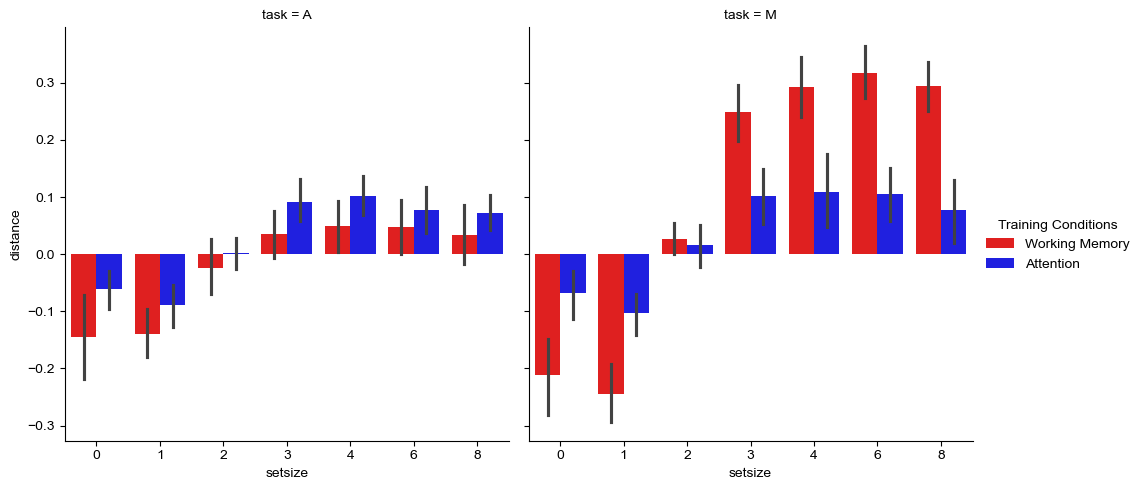

In [ ]:
g = sns.FacetGrid(
    combined_df,
    col="task",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "training_conditions",
    palette={"Working Memory": "red", "Attention": "blue"},
    order=["0", "1", "2", "3", "4", "6", "8"],
    hue_order=["Working Memory", "Attention"],
)
_ = g.add_legend(title="Training Conditions")
plt.savefig(f"figures/{RUN_DESCRIPTION}_model_comparison_barplot_byTask.png", bbox_inches="tight", transparent=True)
plt.show()
plt.close()

In [ ]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

## Repeated measures anovas for a given task, with a factor for the training conditions

In [ ]:
pg.rm_anova(
    data=combined_df.query("task == 'A'"), dv="distance", within=["setsize", "training_conditions"], subject="subject"
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,2.423108,6,174,0.403851,38.562830,1.436252e-29,2.925458e-18,0.275367,0.584658
1,training_conditions,0.245527,1,29,0.245527,3.950801,5.636455e-02,5.636455e-02,0.037078,1.000000
2,setsize * training_conditions,0.033763,6,174,0.005627,0.792703,5.767804e-01,5.362186e-01,0.005267,0.691689


In [ ]:
pg.rm_anova(
    data=combined_df.query("task == 'M'"), dv="distance", within=["setsize", "training_conditions"], subject="subject"
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,10.038730,6,174,1.673122,82.784711,2.263559e-48,1.766042e-16,0.565098,0.306490
1,training_conditions,0.499401,1,29,0.499401,13.370842,1.007448e-03,1.007448e-03,0.060716,1.000000
2,setsize * training_conditions,2.310395,6,174,0.385066,42.112870,1.793510e-31,1.842091e-12,0.230205,0.348236


# Repeat the cross-model comparisons, but with eyes

In [ ]:
compare_models = True

if compare_models:
    attn_interp = mvEEG.Interpreter(
        data_dir=ROOT,
        experiment_name=EXPERIMENT_NAME,
        descriptions=["A1vsA3"],
        labels=[0, 1],
        trial_phases={"Stim": (0, 200)},
        key_set=["times", "predsEYES"],
    )
    preds_attn, times = attn_interp.dataset.get_data(None, keys=["predsEYES", "times"])
    preds_attn_per_sub = preds_attn.mean(2).mean(1)[:, delay_window, :].mean(1)
    full_df_attn = pd.DataFrame(preds_attn_per_sub, columns=conditions)
    full_df_attn["subject"] = full_df_attn.index.values
    melted_df_attn = full_df_attn.melt(id_vars="subject", var_name="condition", value_name="distance")
    melted_df_attn.loc[:, "task"] = melted_df_attn.condition.str[0]
    melted_df_attn.loc[:, "setsize"] = melted_df_attn.condition.str[1]
    melted_df_attn["training_conditions"] = "Attention"

    wm_interp = mvEEG.Interpreter(
        data_dir=ROOT,
        experiment_name=EXPERIMENT_NAME,
        descriptions=["M1vsM3"],
        labels=[0, 1],
        trial_phases={"Stim": (0, 200)},
        key_set=["predsEYES"],
    )
    preds_wm = wm_interp.dataset.get_data(None, keys=["predsEYES"])
    preds_wm_per_sub = preds_wm.mean(2).mean(1)[:, delay_window, :].mean(1)
    full_df_wm = pd.DataFrame(preds_wm_per_sub, columns=conditions)
    full_df_wm["subject"] = full_df_wm.index.values
    melted_df_wm = full_df_wm.melt(id_vars="subject", var_name="condition", value_name="distance")
    melted_df_wm.loc[:, "task"] = melted_df_wm.condition.str[0]
    melted_df_wm.loc[:, "setsize"] = melted_df_wm.condition.str[1]
    melted_df_wm["training_conditions"] = "Working Memory"

    combined_df = pd.concat([melted_df_attn, melted_df_wm], axis=0).reset_index(drop=True)

### Grouping by training conditions (attention or working memory)

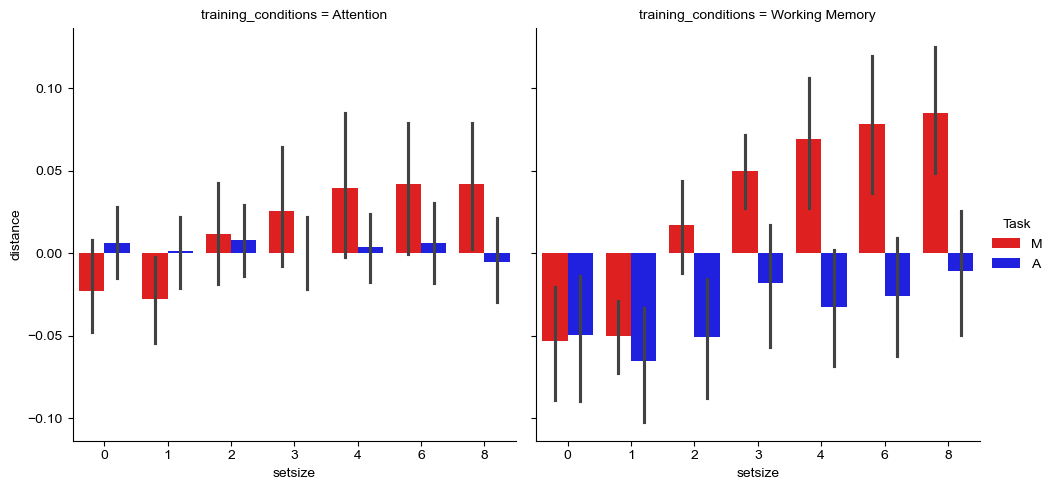

In [ ]:
g = sns.FacetGrid(
    combined_df,
    col="training_conditions",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "task",
    palette={"M": "red", "A": "blue"},
    order=["0", "1", "2", "3", "4", "6", "8"],
    hue_order=["M", "A"],
)
_ = g.add_legend(title="Task")
plt.savefig(
    f"figures/{RUN_DESCRIPTION}_model_comparison_barplot_byModel_EYES.png", bbox_inches="tight", transparent=True
)
plt.show()
plt.close()

In [ ]:
pg.rm_anova(
    data=combined_df.query("training_conditions == 'Attention'"),
    dv="distance",
    within=["setsize", "task"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.077271,6,174,0.012878,2.424219,0.028237,0.059186,0.025464,0.597542
1,task,0.017237,1,29,0.017237,1.117614,0.299160,0.299160,0.005795,1.000000
2,setsize * task,0.090044,6,174,0.015007,4.744300,0.000168,0.000928,0.029549,0.730285


In [ ]:
pg.rm_anova(
    data=combined_df.query("training_conditions == 'Working Memory'"),
    dv="distance",
    within=["setsize", "task"],
    subject="subject",
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.527670,6,174,0.087945,12.029953,2.752842e-11,9.056838e-07,0.117182,0.511544
1,task,0.431608,1,29,0.431608,17.073573,2.792292e-04,2.792292e-04,0.097939,1.000000
2,setsize * task,0.164726,6,174,0.027454,7.170097,7.572649e-07,2.528093e-05,0.039789,0.692476


## grouping by task conditions

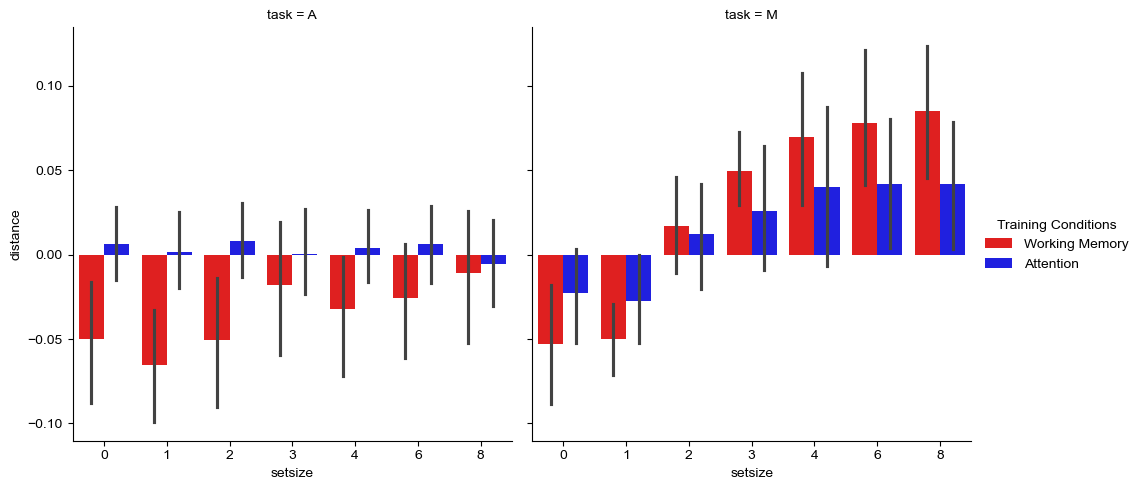

In [ ]:
g = sns.FacetGrid(
    combined_df,
    col="task",
    height=5,
    aspect=1,
)
g.map(
    sns.barplot,
    "setsize",
    "distance",
    "training_conditions",
    palette={"Working Memory": "red", "Attention": "blue"},
    order=["0", "1", "2", "3", "4", "6", "8"],
    hue_order=["Working Memory", "Attention"],
)
_ = g.add_legend(title="Training Conditions")
plt.savefig(
    f"figures/{RUN_DESCRIPTION}_model_comparison_barplot_byTask_EYES.png", bbox_inches="tight", transparent=True
)
plt.show()
plt.close()

In [ ]:
pg.rm_anova(
    data=combined_df.query("task == 'A'"), dv="distance", within=["setsize", "training_conditions"], subject="subject"
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.028007,6,174,0.004668,0.934280,0.471807,0.452858,0.009078,0.734377
1,training_conditions,0.160366,1,29,0.160366,5.824845,0.022345,0.022345,0.049840,1.000000
2,setsize * training_conditions,0.045718,6,174,0.007620,2.961933,0.008875,0.018922,0.014734,0.729689


In [ ]:
pg.rm_anova(
    data=combined_df.query("task == 'M'"), dv="distance", within=["setsize", "training_conditions"], subject="subject"
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/distribution.py:508: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  .diff(axis=1)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,setsize,0.710738,6,174,0.118456,14.277780,3.336130e-13,0.000002,0.154977,0.400722
1,training_conditions,0.015681,1,29,0.015681,0.479945,4.939582e-01,0.493958,0.004030,1.000000
2,setsize * training_conditions,0.075248,6,174,0.012541,3.344494,3.827599e-03,0.012125,0.019047,0.674310
